starting with error correction by using hamming decoder

encoding

In [4]:
import numpy as np


# ============================================================
# FILES
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/rules_bitpacked.npy"
OUTPUT_FILE = "/home/<user>/iot_dataset/error_codes/hamming_encoded.npy"


# ============================================================
# HAMMING(7,4) ENCODER
# ============================================================

def hamming_encode(data_bits):

    data_bits = np.asarray(data_bits, dtype=np.uint8)

    # Must be divisible by 4
    assert len(data_bits) % 4 == 0

    blocks = data_bits.reshape(-1, 4)

    # Data bits
    d1 = blocks[:, 0]
    d2 = blocks[:, 1]
    d3 = blocks[:, 2]
    d4 = blocks[:, 3]

    # Even parity bits
    p1 = d1 ^ d2 ^ d4
    p2 = d1 ^ d3 ^ d4
    p4 = d2 ^ d3 ^ d4

    # Hamming(7,4)
    #
    # Position:
    # 1  2  3  4  5  6  7
    # P1 P2 D1 P4 D2 D3 D4

    encoded = np.column_stack([
        p1,
        p2,
        d1,
        p4,
        d2,
        d3,
        d4
    ])

    return encoded.reshape(-1)


# ============================================================
# LOAD ORIGINAL FILE
# ============================================================

print("=" * 60)
print("HAMMING ENCODER")
print("=" * 60)

data = np.load(INPUT_FILE)

print("\nOriginal file :", INPUT_FILE)
print("Packed shape  :", data.shape)
print("Packed dtype  :", data.dtype)
print("Packed bytes  :", data.nbytes)


# ============================================================
# UNPACK
# ============================================================

bits = np.unpackbits(data, axis=-1)

# Original logical data is 526 bits.
bits = bits[..., :526]

print("\nLogical shape :", bits.shape)

original_shape = bits.shape

# Flatten
bits = bits.reshape(-1)

print("Total bits    :", len(bits))


# ============================================================
# HAMMING ENCODE
# ============================================================

encoded_bits = hamming_encode(bits)

print("\nEncoding complete.")

print("Original bits :", len(bits))
print("Encoded bits  :", len(encoded_bits))

print(
    "Expansion     : {:.2f}x".format(
        len(encoded_bits) / len(bits)
    )
)


# ============================================================
# SAVE
# ============================================================

np.save(OUTPUT_FILE, encoded_bits)

print("\nSaved:")
print(OUTPUT_FILE)

print("\nDone.")

HAMMING ENCODER

Original file : /home/<user>/iot_dataset/rules_bitpacked.npy
Packed shape  : (6, 6000, 66)
Packed dtype  : uint8
Packed bytes  : 2376000

Logical shape : (6, 6000, 526)
Total bits    : 18936000

Encoding complete.
Original bits : 18936000
Encoded bits  : 33138000
Expansion     : 1.75x

Saved:
/home/<user>/iot_dataset/error_codes/hamming_encoded.npy

Done.


corrupting

In [6]:
import numpy as np


# ============================================================
# FILES
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/error_codes/hamming_encoded.npy"
OUTPUT_FILE = "/home/<user>/iot_dataset/error_codes/hamming_corrupted2.npy"


# ============================================================
# CORRUPTION LOCATIONS
# ============================================================
#
# These are positions in the FLATTENED
# HAMMING-ENCODED bitstream.
#
# Example:
#
#   0       = first encoded bit
#   1       = second encoded bit
#   100     = encoded bit 100
#
# Make sure the positions are within the file.
#

CORRUPT_POSITIONS = [
   10,70000,80000,30000
]


# ============================================================
# LOAD ENCODED DATA
# ============================================================

print("=" * 60)
print("BIT CORRUPTION INJECTOR")
print("=" * 60)

encoded = np.load(INPUT_FILE)

print("\nInput file   :", INPUT_FILE)
print("Total encoded bits:", len(encoded))


# ============================================================
# COPY DATA
# ============================================================

corrupted = encoded.copy()


# ============================================================
# FLIP SELECTED BITS
# ============================================================

print("\nInjecting corruption...")
print("-" * 60)

valid_positions = []

for position in CORRUPT_POSITIONS:

    if position < 0 or position >= len(corrupted):

        print(
            f"WARNING: position {position} is outside the file"
        )

        continue

    # Flip bit
    #
    # 0 -> 1
    # 1 -> 0
    #
    corrupted[position] ^= 1

    valid_positions.append(position)

    print(
        f"Flipped encoded bit position: {position}"
    )


# ============================================================
# SAVE CORRUPTED FILE
# ============================================================

np.save(OUTPUT_FILE, corrupted)

print("-" * 60)

print("\nCorruption complete.")

print("Bits flipped :", len(valid_positions))

print("\nSaved corrupted file:")
print(OUTPUT_FILE)

BIT CORRUPTION INJECTOR

Input file   : /home/<user>/iot_dataset/error_codes/hamming_encoded.npy
Total encoded bits: 33138000

Injecting corruption...
------------------------------------------------------------
Flipped encoded bit position: 10
Flipped encoded bit position: 70000
Flipped encoded bit position: 80000
Flipped encoded bit position: 30000
------------------------------------------------------------

Corruption complete.
Bits flipped : 4

Saved corrupted file:
/home/<user>/iot_dataset/error_codes/hamming_corrupted2.npy


corruption bit packing  above no packing

In [4]:
import numpy as np


# ============================================================
# FILES
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/error_codes/hamming_encoded.npy"
OUTPUT_FILE = "/home/<user>/iot_dataset/error_codes/hamming_corrupted1.bin"


# ============================================================
# CORRUPTION LOCATIONS
# ============================================================
#
# Positions are GLOBAL BIT POSITIONS in the Hamming-encoded
# bitstream.
#
# Example:
#
#   position 0      -> first Hamming encoded bit
#   position 1      -> second Hamming encoded bit
#   position 100    -> encoded bit 100
#
# These positions are NOT byte positions.
#

CORRUPT_POSITIONS = [
    100,250,5000,450,60000
]


# ============================================================
# LOAD HAMMING ENCODED DATA
# ============================================================

print("=" * 60)
print("HAMMING BIT-PACKED CORRUPTION INJECTOR")
print("=" * 60)

encoded = np.load(INPUT_FILE)

print("\nInput file:")
print(INPUT_FILE)

print("\nInput representation:")
print("dtype :", encoded.dtype)
print("elements :", len(encoded))

print("\nOriginal encoded bits :", len(encoded))


# ============================================================
# MAKE SURE DATA IS 0/1
# ============================================================

if not np.all((encoded == 0) | (encoded == 1)):
    raise ValueError("Input contains values other than 0 and 1.")


# ============================================================
# PACK HAMMING BITS
# ============================================================
#
# 8 Hamming bits -> 1 byte
#
# NumPy uses MSB-first packing:
#
# bit 0 -> bit 7
# bit 1 -> bit 6
# ...
# bit 7 -> bit 0
#

packed = np.packbits(encoded, bitorder="big")


# ============================================================
# SIZE INFORMATION
# ============================================================

total_bits = len(encoded)
packed_bytes = len(packed)

print("\nPacked representation:")
print("Encoded bits  :", total_bits)
print("Packed bytes  :", packed_bytes)
print("Packed MiB    :", packed_bytes / (1024 * 1024))
print("Packed MB     :", packed_bytes / 1_000_000)


# ============================================================
# COPY PACKED DATA
# ============================================================

corrupted = packed.copy()


# ============================================================
# FLIP SELECTED BITS
# ============================================================

print("\nInjecting corruption...")
print("-" * 60)

valid_positions = []

for position in CORRUPT_POSITIONS:

    if position < 0 or position >= total_bits:

        print(
            f"WARNING: position {position} is outside "
            f"the encoded bitstream"
        )

        continue

    # --------------------------------------------------------
    # Convert GLOBAL BIT POSITION -> BYTE + BIT
    # --------------------------------------------------------

    byte_index = position // 8
    bit_index = position % 8

    # NumPy packbits(bitorder="big"):
    #
    # position 0 -> MSB
    # position 1 -> next bit
    #
    # Therefore:
    #
    # bit mask = 1 << (7 - bit_index)

    mask = 1 << (7 - bit_index)

    # --------------------------------------------------------
    # Flip bit
    # --------------------------------------------------------

    corrupted[byte_index] ^= mask

    valid_positions.append(position)

    print(
        f"Flipped bit {position:8d} "
        f"(byte {byte_index:8d}, "
        f"bit {bit_index})"
    )


# ============================================================
# SAVE CORRUPTED PACKED BINARY FILE
# ============================================================

corrupted.tofile(OUTPUT_FILE)


# ============================================================
# FINAL INFORMATION
# ============================================================

print("-" * 60)

print("\nCorruption complete.")

print("Bits flipped :", len(valid_positions))

print("\nSaved corrupted packed file:")
print(OUTPUT_FILE)

print("\nOutput size:")
print("Bytes :", len(corrupted))
print("MiB   :", len(corrupted) / (1024 * 1024))
print("MB    :", len(corrupted) / 1_000_000)

print("\nCorrupted positions:")
print(valid_positions)

HAMMING BIT-PACKED CORRUPTION INJECTOR

Input file:
/home/<user>/iot_dataset/error_codes/hamming_encoded.npy

Input representation:
dtype : uint8
elements : 33138000

Original encoded bits : 33138000

Packed representation:
Encoded bits  : 33138000
Packed bytes  : 4142250
Packed MiB    : 3.950357437133789
Packed MB     : 4.14225

Injecting corruption...
------------------------------------------------------------
Flipped bit      100 (byte       12, bit 4)
Flipped bit      250 (byte       31, bit 2)
Flipped bit     5000 (byte      625, bit 0)
Flipped bit      450 (byte       56, bit 2)
Flipped bit    60000 (byte     7500, bit 0)
------------------------------------------------------------

Corruption complete.
Bits flipped : 5

Saved corrupted packed file:
/home/<user>/iot_dataset/error_codes/hamming_corrupted1.bin

Output size:
Bytes : 4142250
MiB   : 3.950357437133789
MB    : 4.14225

Corrupted positions:
[100, 250, 5000, 450, 60000]


error checking and correcting

In [16]:
import numpy as np
import time


# ============================================================
# FILES
# ============================================================

CORRUPTED_FILE = "/home/<user>/iot_dataset/error_codes/hamming_corrupted.npy"
OUTPUT_FILE = "/home/<user>/iot_dataset/error_codes/hamming_decoded.npy"
ORIGINAL_FILE = "/home/<user>/iot_dataset/rules_bitpacked.npy"


# ============================================================
# HAMMING DECODER
# ============================================================

def hamming_decode(encoded_bits):

    encoded_bits = np.asarray(
        encoded_bits,
        dtype=np.uint8
    )

    blocks = encoded_bits.reshape(-1, 7).copy()

    # --------------------------------------------------------
    # Extract bits
    # --------------------------------------------------------

    b1 = blocks[:, 0]
    b2 = blocks[:, 1]
    b3 = blocks[:, 2]
    b4 = blocks[:, 3]
    b5 = blocks[:, 4]
    b6 = blocks[:, 5]
    b7 = blocks[:, 6]

    # --------------------------------------------------------
    # Syndrome calculation
    # --------------------------------------------------------

    s1 = b1 ^ b3 ^ b5 ^ b7
    s2 = b2 ^ b3 ^ b6 ^ b7
    s4 = b4 ^ b5 ^ b6 ^ b7

    error_positions = (
        s1.astype(np.int32)
        + 2 * s2.astype(np.int32)
        + 4 * s4.astype(np.int32)
    )

    # ========================================================
    # FIND ERRORS
    # ========================================================

    error_blocks = np.nonzero(error_positions)[0]

    # ========================================================
    # CORRECT ERRORS
    # ========================================================

    for block_index in error_blocks:

        position = error_positions[block_index]

        blocks[
            block_index,
            position - 1
        ] ^= 1

    # ========================================================
    # EXTRACT DATA
    # ========================================================

    decoded = blocks[:, [2, 4, 5, 6]]

    return decoded.reshape(-1), error_positions


# ============================================================
# LOAD CORRUPTED FILE
# ============================================================

print("=" * 70)
print("HAMMING DECODER PERFORMANCE TEST")
print("=" * 70)

corrupted = np.load(CORRUPTED_FILE)

print("\nEncoded bits:", len(corrupted))
print("Codewords   :", len(corrupted) // 7)


# ============================================================
# WARM-UP
# ============================================================

# Run once before timing to reduce one-time Python/NumPy
# initialization effects.

_ = hamming_decode(corrupted)


# ============================================================
# TIMED DECODING
# ============================================================

start = time.perf_counter()

decoded_bits, error_positions = hamming_decode(
    corrupted
)

end = time.perf_counter()


decode_time = end - start


# ============================================================
# ERROR INFORMATION
# ============================================================

error_blocks = np.nonzero(error_positions)[0]

print("\n" + "=" * 70)
print("ERROR DETECTION")
print("=" * 70)

if len(error_blocks) == 0:

    print("\nNO ERRORS DETECTED.")

else:

    print(
        f"\n{len(error_blocks)} erroneous codewords detected."
    )

    print("\nError positions:")

    for block_index in error_blocks:

        position = error_positions[block_index]

        global_position = (
            block_index * 7
            + (position - 1)
        )

        print(
            f"Codeword {block_index:8d} | "
            f"Position {position} | "
            f"Global bit {global_position}"
        )


# ============================================================
# TIMING RESULT
# ============================================================

print("\n" + "=" * 70)
print("TIMING")
print("=" * 70)

print(
    f"\nDetection + correction time : "
    f"{decode_time * 1000:.6f} ms"
)

print(
    f"Detection + correction time : "
    f"{decode_time * 1_000_000:.3f} us"
)

print(
    f"\nThroughput : "
    f"{len(corrupted) / decode_time / 1e6:.3f} Mbit/s"
)

print(
    f"Codeword processing rate : "
    f"{(len(corrupted) // 7) / decode_time / 1e6:.3f} "
    f"Mcodewords/s"
)


# ============================================================
# RECONSTRUCT DATA
# ============================================================

decoded_matrix = decoded_bits.reshape(
    6,
    6000,
    526
)


# ============================================================
# LOAD ORIGINAL
# ============================================================

original = np.load(ORIGINAL_FILE)

original_bits = np.unpackbits(
    original,
    axis=-1
)

corrected_bits = original_bits.copy()

corrected_bits[..., :526] = decoded_matrix

corrected_packed = np.packbits(
    corrected_bits,
    axis=-1
)


# ============================================================
# SAVE
# ============================================================

np.save(
    OUTPUT_FILE,
    corrected_packed
)


# ============================================================
# VERIFY
# ============================================================

original_logical = original_bits[..., :526]

corrected_logical = corrected_bits[..., :526]

mismatch = np.count_nonzero(
    original_logical != corrected_logical
)


print("\n" + "=" * 70)
print("VERIFICATION")
print("=" * 70)

if mismatch == 0:

    print("\nSUCCESS!")
    print("All errors were corrected.")
    print("Recovered data matches the original.")

else:

    print("\nFAILURE!")
    print(
        f"Remaining mismatched bits: {mismatch}"
    )

HAMMING DECODER PERFORMANCE TEST

Encoded bits: 33138000
Codewords   : 4734000

ERROR DETECTION

4 erroneous codewords detected.

Error positions:
Codeword       14 | Position 3 | Global bit 100
Codeword      142 | Position 7 | Global bit 1000
Codeword      143 | Position 3 | Global bit 1003
Codeword    14286 | Position 2 | Global bit 100003

TIMING

Detection + correction time : 57.727113 ms
Detection + correction time : 57727.113 us

Throughput : 574.046 Mbit/s
Codeword processing rate : 82.007 Mcodewords/s

VERIFICATION

FAILURE!
Remaining mismatched bits: 3


above we cant correct 2 codes in same code word 

In [17]:
pip install galois

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 11.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 50.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 MB 24.0 MB/s eta 0:00:00:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [20]:
import galois
print(galois.__version__)

0.4.11


In [23]:
import numpy as np
import galois
import time
import os

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/rules_bitpacked.npy"
OUTPUT_FILE = "/home/<user>/iot_dataset/error_codes/rules_bch_255_191_t8_encoded.npy"

N = 255
K = 191
T = 8

# ============================================================
# LOAD DATA
# ============================================================

packed = np.load(INPUT_FILE)

print("=" * 60)
print("BCH ENCODING")
print("=" * 60)

print(f"Input file        : {INPUT_FILE}")
print(f"Input shape       : {packed.shape}")
print(f"Input dtype       : {packed.dtype}")

# Original logical dimensions
NUM_CLASSES = 6
CLAUSES = 6000
LOGICAL_BITS = 526

# Unpack bytes -> bits
bits = np.unpackbits(packed, axis=-1)

# Remove the 2 padding bits
bits = bits[..., :LOGICAL_BITS]

# Flatten
data_bits = bits.reshape(-1)

original_length = len(data_bits)

print(f"Logical bits      : {original_length:,}")

# ============================================================
# CREATE BCH CODE
# ============================================================

bch = galois.BCH(N, K)

print()
print(f"BCH code          : BCH({bch.n}, {bch.k})")
print(f"Correctable t     : {bch.t}")
print(f"Code rate         : {bch.k / bch.n:.4f}")

# ============================================================
# PAD DATA
# ============================================================

num_codewords = int(np.ceil(len(data_bits) / K))
padded_length = num_codewords * K
padding_bits = padded_length - len(data_bits)

if padding_bits > 0:
    data_bits = np.pad(
        data_bits,
        (0, padding_bits),
        constant_values=0
    )

print(f"Codewords         : {num_codewords:,}")
print(f"Padding bits      : {padding_bits}")

# ============================================================
# RESHAPE INTO BCH DATA BLOCKS
# ============================================================

data_blocks = data_bits.reshape(-1, K)

# Convert to GF(2)
data_blocks = galois.GF2(data_blocks)

# ============================================================
# BCH ENCODING + TIMING
# ============================================================

start = time.perf_counter()

encoded_blocks = bch.encode(data_blocks)

elapsed = time.perf_counter() - start

# Convert back to numpy
encoded_bits = np.asarray(encoded_blocks, dtype=np.uint8)

encoded_bits = encoded_bits.reshape(-1)

# ============================================================
# RESULTS
# ============================================================

encoded_length = len(encoded_bits)

print()
print(f"Encoded bits      : {encoded_length:,}")
print(f"Encoded bytes     : {encoded_length / 8 / 1024 / 1024:.3f} MiB")

print()
print(f"Encoding time     : {elapsed * 1000:.3f} ms")

throughput = original_length / elapsed / 1e6

print(f"Throughput        : {throughput:.3f} Mbit/s")

print()
print(f"Expansion         : {encoded_length / original_length:.4f}x")
print(f"Overhead          : {(encoded_length / original_length - 1) * 100:.2f}%")

# ============================================================
# SAVE
# ============================================================

np.save(OUTPUT_FILE, encoded_bits)

print()
print(f"Saved as          : {OUTPUT_FILE}")
print("=" * 60)

BCH ENCODING
Input file        : /home/<user>/iot_dataset/rules_bitpacked.npy
Input shape       : (6, 6000, 66)
Input dtype       : uint8
Logical bits      : 18,936,000

BCH code          : BCH(255, 191)
Correctable t     : 8
Code rate         : 0.7490
Codewords         : 99,142
Padding bits      : 122

Encoded bits      : 25,281,210
Encoded bytes     : 3.014 MiB

Encoding time     : 48.382 ms
Throughput        : 391.385 Mbit/s

Expansion         : 1.3351x
Overhead          : 33.51%

Saved as          : /home/<user>/iot_dataset/error_codes/rules_bch_255_191_t8_encoded.npy


In [36]:
import numpy as np

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/error_codes/rules_bch_255_191_t8_encoded.npy"
OUTPUT_FILE = "/home/<user>/iot_dataset/error_codes/rules_bch_255_191_t8_corrupted.npy"

N = 255
T = 8

# Positions INSIDE THE FIRST BCH CODEWORD
ERROR_POSITIONS = [
    10,
    20,
  78,140,
    50,
    60,
    70,
    80
]

# ============================================================
# LOAD
# ============================================================

encoded = np.load(INPUT_FILE).copy()

print("=" * 60)
print("BCH CORRUPTION")
print("=" * 60)

print(f"Input file        : {INPUT_FILE}")
print(f"Total encoded bits: {len(encoded):,}")
print(f"Errors requested  : {len(ERROR_POSITIONS)}")

# ============================================================
# INJECT ERRORS
# ============================================================

for pos in ERROR_POSITIONS:

    if pos >= N:
        raise ValueError(f"Position {pos} outside BCH codeword")

    encoded[pos] ^= 1

    print(
        f"Flipped global bit {pos:3d} "
        f"(codeword 0, position {pos})"
    )

# ============================================================
# SAVE
# ============================================================

np.save(OUTPUT_FILE, encoded)

print()
print(f"Saved as          : {OUTPUT_FILE}")
print("=" * 60)

BCH CORRUPTION
Input file        : /home/<user>/iot_dataset/error_codes/rules_bch_255_191_t8_encoded.npy
Total encoded bits: 25,281,210
Errors requested  : 8
Flipped global bit  10 (codeword 0, position 10)
Flipped global bit  20 (codeword 0, position 20)
Flipped global bit  78 (codeword 0, position 78)
Flipped global bit 140 (codeword 0, position 140)
Flipped global bit  50 (codeword 0, position 50)
Flipped global bit  60 (codeword 0, position 60)
Flipped global bit  70 (codeword 0, position 70)
Flipped global bit  80 (codeword 0, position 80)

Saved as          : /home/<user>/iot_dataset/error_codes/rules_bch_255_191_t8_corrupted.npy


In [38]:
import numpy as np
import galois
import time

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/error_codes/rules_bch_255_191_t8_corrupted.npy"
OUTPUT_FILE = "/home/<user>/iot_dataset/error_codes/bch_decoded.npy"
ORIGINAL_FILE = "/home/<user>/iot_dataset/rules_bitpacked.npy"

N = 255
K = 191
T = 8

NUM_CLASSES = 6
CLAUSES = 6000
LOGICAL_BITS = 526

# ============================================================
# LOAD
# ============================================================

corrupted = np.load(INPUT_FILE)

print("=" * 60)
print("BCH DECODING")
print("=" * 60)

print(f"Input file        : {INPUT_FILE}")
print(f"Encoded bits      : {len(corrupted):,}")

# ============================================================
# BCH CODE
# ============================================================

bch = galois.BCH(N, K)

num_codewords = len(corrupted) // N

print(f"BCH code          : BCH({bch.n},{bch.k})")
print(f"Correctable t     : {bch.t}")
print(f"Codewords         : {num_codewords:,}")

# ============================================================
# RESHAPE
# ============================================================

received_np = corrupted.reshape(-1, N)

received = galois.GF2(received_np)

# ============================================================
# BCH DECODING
# ============================================================

print()
print("Starting BCH decoding...")

start = time.perf_counter()

decoded_blocks = bch.decode(received)

elapsed = time.perf_counter() - start

# ============================================================
# FIND CORRECTED ERRORS
# ============================================================

decoded_codewords = np.asarray(
    bch.encode(decoded_blocks),
    dtype=np.uint8
)

received_codewords = np.asarray(
    received,
    dtype=np.uint8
)

# Compare received vs corrected codewords
differences = (
    received_codewords != decoded_codewords
)

# Number of corrected errors in each codeword
errors_per_codeword = np.sum(
    differences,
    axis=1
)

error_codewords = np.where(
    errors_per_codeword > 0
)[0]

# ============================================================
# PRINT ERROR INFORMATION
# ============================================================

print()
print("=" * 60)
print("ERROR DETECTION / CORRECTION")
print("=" * 60)

print(
    f"Corrupted codewords : "
    f"{len(error_codewords):,}"
)

print(
    f"Total corrected bits: "
    f"{np.sum(errors_per_codeword):,}"
)

print()

if len(error_codewords) == 0:

    print("No errors detected.")

else:

    for cw in error_codewords:

        positions = np.where(
            differences[cw]
        )[0]

        global_positions = (
            cw * N + positions
        )

        print(
            f"Codeword {cw:,}: "
            f"{len(positions)} error(s)"
        )

        print(
            f"  Positions in codeword : "
            f"{positions.tolist()}"
        )

        print(
            f"  Global encoded bits   : "
            f"{global_positions.tolist()}"
        )

# ============================================================
# DECODE DATA BITS
# ============================================================

decoded_bits = np.asarray(
    decoded_blocks,
    dtype=np.uint8
)

decoded_bits = decoded_bits.reshape(-1)

# ============================================================
# REMOVE BCH PADDING
# ============================================================

original_length = (
    NUM_CLASSES *
    CLAUSES *
    LOGICAL_BITS
)

decoded_bits = decoded_bits[:original_length]

# ============================================================
# RESTORE ORIGINAL SHAPE
# ============================================================

decoded_bits = decoded_bits.reshape(
    NUM_CLASSES,
    CLAUSES,
    LOGICAL_BITS
)

# ============================================================
# REPACK TO ORIGINAL FORMAT
# ============================================================

original_packed = np.load(
    ORIGINAL_FILE
)

decoded_packed_bits = np.unpackbits(
    np.zeros_like(original_packed),
    axis=-1
)

# Insert corrected logical bits
decoded_packed_bits[
    ..., :LOGICAL_BITS
] = decoded_bits

# Preserve original 2 padding bits
original_full_bits = np.unpackbits(
    original_packed,
    axis=-1
)

decoded_packed_bits[
    ..., LOGICAL_BITS:
] = original_full_bits[
    ..., LOGICAL_BITS:
]

decoded_packed = np.packbits(
    decoded_packed_bits,
    axis=-1
)

# ============================================================
# SAVE
# ============================================================

np.save(
    OUTPUT_FILE,
    decoded_packed
)

# ============================================================
# TIMING
# ============================================================

print()
print("=" * 60)
print("PERFORMANCE")
print("=" * 60)

print(
    f"Decoding time     : "
    f"{elapsed * 1000:.3f} ms"
)

throughput = (
    original_length /
    elapsed /
    1e6
)

print(
    f"Throughput        : "
    f"{throughput:.3f} Mbit/s"
)

cw_throughput = (
    num_codewords /
    elapsed /
    1e6
)

print(
    f"Codewords/sec     : "
    f"{cw_throughput:.6f} Mcodewords/s"
)

# ============================================================
# VERIFICATION
# ============================================================

original = np.load(
    ORIGINAL_FILE
)

match = np.array_equal(
    original,
    decoded_packed
)

print()
print("=" * 60)
print("VERIFICATION")
print("=" * 60)

print(
    f"Verification      : "
    f"{'SUCCESS' if match else 'FAILURE'}"
)

if not match:

    original_bits = np.unpackbits(
        original,
        axis=-1
    )[..., :LOGICAL_BITS]

    final_bits = np.unpackbits(
        decoded_packed,
        axis=-1
    )[..., :LOGICAL_BITS]

    mismatches = np.sum(
        original_bits != final_bits
    )

    print(
        f"Remaining mismatches: "
        f"{mismatches:,}"
    )

print()
print(
    f"Saved as          : "
    f"{OUTPUT_FILE}"
)

print("=" * 60)

BCH DECODING
Input file        : /home/<user>/iot_dataset/error_codes/rules_bch_255_191_t8_corrupted.npy
Encoded bits      : 25,281,210
BCH code          : BCH(255,191)
Correctable t     : 8
Codewords         : 99,142

Starting BCH decoding...

ERROR DETECTION / CORRECTION
Corrupted codewords : 1
Total corrected bits: 8

Codeword 0: 8 error(s)
  Positions in codeword : [10, 20, 50, 60, 70, 78, 80, 140]
  Global encoded bits   : [10, 20, 50, 60, 70, 78, 80, 140]

PERFORMANCE
Decoding time     : 136443.574 ms
Throughput        : 0.139 Mbit/s
Codewords/sec     : 0.000727 Mcodewords/s

VERIFICATION
Verification      : SUCCESS

Saved as          : /home/<user>/iot_dataset/error_codes/bch_decoded.npy


trying for less error correction within code word

In [39]:
import numpy as np
import galois
import time
import os

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/rules_bitpacked.npy"
OUTPUT_FILE = "/home/<user>/iot_dataset/error_codes/rules_bch_255_239_t2_encoded.npy"

N = 255
K = 239
T = 2

# ============================================================
# LOAD DATA
# ============================================================

packed = np.load(INPUT_FILE)

print("=" * 60)
print("BCH ENCODING")
print("=" * 60)

print(f"Input file        : {INPUT_FILE}")
print(f"Input shape       : {packed.shape}")
print(f"Input dtype       : {packed.dtype}")

# Original logical dimensions
NUM_CLASSES = 6
CLAUSES = 6000
LOGICAL_BITS = 526

# Unpack bytes -> bits
bits = np.unpackbits(packed, axis=-1)

# Remove the 2 padding bits
bits = bits[..., :LOGICAL_BITS]

# Flatten
data_bits = bits.reshape(-1)

original_length = len(data_bits)

print(f"Logical bits      : {original_length:,}")

# ============================================================
# CREATE BCH CODE
# ============================================================

bch = galois.BCH(N, K)

print()
print(f"BCH code          : BCH({bch.n}, {bch.k})")
print(f"Correctable t     : {bch.t}")
print(f"Code rate         : {bch.k / bch.n:.4f}")

# ============================================================
# PAD DATA
# ============================================================

num_codewords = int(np.ceil(len(data_bits) / K))
padded_length = num_codewords * K
padding_bits = padded_length - len(data_bits)

if padding_bits > 0:
    data_bits = np.pad(
        data_bits,
        (0, padding_bits),
        constant_values=0
    )

print(f"Codewords         : {num_codewords:,}")
print(f"Padding bits      : {padding_bits}")

# ============================================================
# RESHAPE INTO BCH DATA BLOCKS
# ============================================================

data_blocks = data_bits.reshape(-1, K)

# Convert to GF(2)
data_blocks = galois.GF2(data_blocks)

# ============================================================
# BCH ENCODING + TIMING
# ============================================================

start = time.perf_counter()

encoded_blocks = bch.encode(data_blocks)

elapsed = time.perf_counter() - start

# Convert back to numpy
encoded_bits = np.asarray(encoded_blocks, dtype=np.uint8)

encoded_bits = encoded_bits.reshape(-1)

# ============================================================
# RESULTS
# ============================================================

encoded_length = len(encoded_bits)

print()
print(f"Encoded bits      : {encoded_length:,}")
print(f"Encoded bytes     : {encoded_length / 8 / 1024 / 1024:.3f} MiB")

print()
print(f"Encoding time     : {elapsed * 1000:.3f} ms")

throughput = original_length / elapsed / 1e6

print(f"Throughput        : {throughput:.3f} Mbit/s")

print()
print(f"Expansion         : {encoded_length / original_length:.4f}x")
print(f"Overhead          : {(encoded_length / original_length - 1) * 100:.2f}%")

# ============================================================
# SAVE
# ============================================================

np.save(OUTPUT_FILE, encoded_bits)

print()
print(f"Saved as          : {OUTPUT_FILE}")
print("=" * 60)

BCH ENCODING
Input file        : /home/<user>/iot_dataset/rules_bitpacked.npy
Input shape       : (6, 6000, 66)
Input dtype       : uint8
Logical bits      : 18,936,000

BCH code          : BCH(255, 239)
Correctable t     : 2
Code rate         : 0.9373
Codewords         : 79,231
Padding bits      : 209

Encoded bits      : 20,203,905
Encoded bytes     : 2.408 MiB

Encoding time     : 21.499 ms
Throughput        : 880.777 Mbit/s

Expansion         : 1.0670x
Overhead          : 6.70%

Saved as          : /home/<user>/iot_dataset/error_codes/rules_bch_255_239_t2_encoded.npy


In [42]:
import numpy as np

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/error_codes/rules_bch_255_239_t2_encoded.npy"
OUTPUT_FILE = "/home/<user>/iot_dataset/error_codes/rules_bch_255_239_t2_corrupted.npy"

N = 255
T = 2

# Positions INSIDE THE FIRST BCH CODEWORD
ERROR_POSITIONS = [
    18,53
]

# ============================================================
# LOAD
# ============================================================

encoded = np.load(INPUT_FILE).copy()

print("=" * 60)
print("BCH CORRUPTION")
print("=" * 60)

print(f"Input file        : {INPUT_FILE}")
print(f"Total encoded bits: {len(encoded):,}")
print(f"Errors requested  : {len(ERROR_POSITIONS)}")

# ============================================================
# INJECT ERRORS
# ============================================================

for pos in ERROR_POSITIONS:

    if pos >= N:
        raise ValueError(f"Position {pos} outside BCH codeword")

    encoded[pos] ^= 1

    print(
        f"Flipped global bit {pos:3d} "
        f"(codeword 0, position {pos})"
    )

# ============================================================
# SAVE
# ============================================================

np.save(OUTPUT_FILE, encoded)

print()
print(f"Saved as          : {OUTPUT_FILE}")
print("=" * 60)

BCH CORRUPTION
Input file        : /home/<user>/iot_dataset/error_codes/rules_bch_255_239_t2_encoded.npy
Total encoded bits: 20,203,905
Errors requested  : 2
Flipped global bit  18 (codeword 0, position 18)
Flipped global bit  53 (codeword 0, position 53)

Saved as          : /home/<user>/iot_dataset/error_codes/rules_bch_255_239_t2_corrupted.npy


In [43]:
import numpy as np
import galois
import time

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/error_codes/rules_bch_255_239_t2_corrupted.npy"
OUTPUT_FILE = "/home/<user>/iot_dataset/error_codes/bch_decoded_255_239_t2.npy"
ORIGINAL_FILE = "/home/<user>/iot_dataset/rules_bitpacked.npy"

N = 255
K = 239
T = 2

NUM_CLASSES = 6
CLAUSES = 6000
LOGICAL_BITS = 526

# ============================================================
# LOAD
# ============================================================

corrupted = np.load(INPUT_FILE)

print("=" * 60)
print("BCH DECODING")
print("=" * 60)

print(f"Input file        : {INPUT_FILE}")
print(f"Encoded bits      : {len(corrupted):,}")

# ============================================================
# BCH CODE
# ============================================================

bch = galois.BCH(N, K)

num_codewords = len(corrupted) // N

print(f"BCH code          : BCH({bch.n},{bch.k})")
print(f"Correctable t     : {bch.t}")
print(f"Codewords         : {num_codewords:,}")

# ============================================================
# RESHAPE
# ============================================================

received_np = corrupted.reshape(-1, N)

received = galois.GF2(received_np)

# ============================================================
# BCH DECODING
# ============================================================

print()
print("Starting BCH decoding...")

start = time.perf_counter()

decoded_blocks = bch.decode(received)

elapsed = time.perf_counter() - start

# ============================================================
# FIND CORRECTED ERRORS
# ============================================================

decoded_codewords = np.asarray(
    bch.encode(decoded_blocks),
    dtype=np.uint8
)

received_codewords = np.asarray(
    received,
    dtype=np.uint8
)

# Compare received vs corrected codewords
differences = (
    received_codewords != decoded_codewords
)

# Number of corrected errors in each codeword
errors_per_codeword = np.sum(
    differences,
    axis=1
)

error_codewords = np.where(
    errors_per_codeword > 0
)[0]

# ============================================================
# PRINT ERROR INFORMATION
# ============================================================

print()
print("=" * 60)
print("ERROR DETECTION / CORRECTION")
print("=" * 60)

print(
    f"Corrupted codewords : "
    f"{len(error_codewords):,}"
)

print(
    f"Total corrected bits: "
    f"{np.sum(errors_per_codeword):,}"
)

print()

if len(error_codewords) == 0:

    print("No errors detected.")

else:

    for cw in error_codewords:

        positions = np.where(
            differences[cw]
        )[0]

        global_positions = (
            cw * N + positions
        )

        print(
            f"Codeword {cw:,}: "
            f"{len(positions)} error(s)"
        )

        print(
            f"  Positions in codeword : "
            f"{positions.tolist()}"
        )

        print(
            f"  Global encoded bits   : "
            f"{global_positions.tolist()}"
        )

# ============================================================
# DECODE DATA BITS
# ============================================================

decoded_bits = np.asarray(
    decoded_blocks,
    dtype=np.uint8
)

decoded_bits = decoded_bits.reshape(-1)

# ============================================================
# REMOVE BCH PADDING
# ============================================================

original_length = (
    NUM_CLASSES *
    CLAUSES *
    LOGICAL_BITS
)

decoded_bits = decoded_bits[:original_length]

# ============================================================
# RESTORE ORIGINAL SHAPE
# ============================================================

decoded_bits = decoded_bits.reshape(
    NUM_CLASSES,
    CLAUSES,
    LOGICAL_BITS
)

# ============================================================
# REPACK TO ORIGINAL FORMAT
# ============================================================

original_packed = np.load(
    ORIGINAL_FILE
)

decoded_packed_bits = np.unpackbits(
    np.zeros_like(original_packed),
    axis=-1
)

# Insert corrected logical bits
decoded_packed_bits[
    ..., :LOGICAL_BITS
] = decoded_bits

# Preserve original 2 padding bits
original_full_bits = np.unpackbits(
    original_packed,
    axis=-1
)

decoded_packed_bits[
    ..., LOGICAL_BITS:
] = original_full_bits[
    ..., LOGICAL_BITS:
]

decoded_packed = np.packbits(
    decoded_packed_bits,
    axis=-1
)

# ============================================================
# SAVE
# ============================================================

np.save(
    OUTPUT_FILE,
    decoded_packed
)

# ============================================================
# TIMING
# ============================================================

print()
print("=" * 60)
print("PERFORMANCE")
print("=" * 60)

print(
    f"Decoding time     : "
    f"{elapsed * 1000:.3f} ms"
)

throughput = (
    original_length /
    elapsed /
    1e6
)

print(
    f"Throughput        : "
    f"{throughput:.3f} Mbit/s"
)

cw_throughput = (
    num_codewords /
    elapsed /
    1e6
)

print(
    f"Codewords/sec     : "
    f"{cw_throughput:.6f} Mcodewords/s"
)

# ============================================================
# VERIFICATION
# ============================================================

original = np.load(
    ORIGINAL_FILE
)

match = np.array_equal(
    original,
    decoded_packed
)

print()
print("=" * 60)
print("VERIFICATION")
print("=" * 60)

print(
    f"Verification      : "
    f"{'SUCCESS' if match else 'FAILURE'}"
)

if not match:

    original_bits = np.unpackbits(
        original,
        axis=-1
    )[..., :LOGICAL_BITS]

    final_bits = np.unpackbits(
        decoded_packed,
        axis=-1
    )[..., :LOGICAL_BITS]

    mismatches = np.sum(
        original_bits != final_bits
    )

    print(
        f"Remaining mismatches: "
        f"{mismatches:,}"
    )

print()
print(
    f"Saved as          : "
    f"{OUTPUT_FILE}"
)

print("=" * 60)

BCH DECODING
Input file        : /home/<user>/iot_dataset/error_codes/rules_bch_255_239_t2_corrupted.npy
Encoded bits      : 20,203,905
BCH code          : BCH(255,239)
Correctable t     : 2
Codewords         : 79,231

Starting BCH decoding...

ERROR DETECTION / CORRECTION
Corrupted codewords : 1
Total corrected bits: 2

Codeword 0: 2 error(s)
  Positions in codeword : [18, 53]
  Global encoded bits   : [18, 53]

PERFORMANCE
Decoding time     : 124381.177 ms
Throughput        : 0.152 Mbit/s
Codewords/sec     : 0.000637 Mcodewords/s

VERIFICATION
Verification      : SUCCESS

Saved as          : /home/<user>/iot_dataset/error_codes/bch_decoded_255_239_t2.npy


the above one is correct lets check other block codes to find faster ones
goingg with reed-solomon

In [44]:
import numpy as np
import galois
import time

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/rules_bitpacked.npy"

OUTPUT_FILE = (
    "/home/<user>/iot_dataset/error_codes/"
    "rules_rs_255_223_encoded.npy"
)

N = 255
K = 223

# Original logical dimensions
NUM_CLASSES = 6
CLAUSES = 6000
LOGICAL_BITS = 526

# ============================================================
# LOAD ORIGINAL DATA
# ============================================================

packed = np.load(INPUT_FILE)

print("=" * 60)
print("REED-SOLOMON ENCODING")
print("=" * 60)

print(f"Input file        : {INPUT_FILE}")
print(f"Input shape       : {packed.shape}")
print(f"Input dtype       : {packed.dtype}")

# ============================================================
# UNPACK LOGICAL BITS
# ============================================================

bits = np.unpackbits(
    packed,
    axis=-1
)

# Remove the 2 padding bits
bits = bits[..., :LOGICAL_BITS]

data_bits = bits.reshape(-1)

original_bits = len(data_bits)

print(f"Logical bits      : {original_bits:,}")

# ============================================================
# CONVERT BITS -> BYTES
# ============================================================

# 18,936,000 bits is divisible by 8
if original_bits % 8 != 0:
    raise ValueError(
        "Logical bit count must be divisible by 8"
    )

data_bytes = np.packbits(
    data_bits
)

print(f"Data bytes        : {len(data_bytes):,}")

# ============================================================
# CREATE REED-SOLOMON CODE
# ============================================================

rs = galois.ReedSolomon(
    N,
    K
)

print()
print(f"RS code           : RS({rs.n},{rs.k})")
print(f"Field             : GF({rs.field.order})")
print(f"Code rate         : {rs.k / rs.n:.4f}")
print(f"Correctable       : {rs.t} symbol errors")
print(f"Parity symbols    : {rs.n - rs.k}")

# ============================================================
# PAD TO MULTIPLE OF K
# ============================================================

num_codewords = int(
    np.ceil(len(data_bytes) / K)
)

padded_bytes = num_codewords * K

padding_bytes = (
    padded_bytes - len(data_bytes)
)

if padding_bytes > 0:

    data_bytes = np.pad(
        data_bytes,
        (0, padding_bytes),
        constant_values=0
    )

print()
print(f"Codewords         : {num_codewords:,}")
print(f"Padding bytes     : {padding_bytes}")

# ============================================================
# RESHAPE
# ============================================================

messages = data_bytes.reshape(
    -1,
    K
)

messages = rs.field(messages)

# ============================================================
# ENCODE + TIMING
# ============================================================

print()
print("Starting RS encoding...")

start = time.perf_counter()

encoded = rs.encode(messages)

elapsed = time.perf_counter() - start

encoded = np.asarray(
    encoded,
    dtype=np.uint8
)

encoded = encoded.reshape(-1)

# ============================================================
# RESULTS
# ============================================================

encoded_bytes = len(encoded)

print()
print("=" * 60)
print("ENCODING RESULTS")
print("=" * 60)

print(f"Input bytes       : {len(data_bytes):,}")
print(f"Encoded bytes     : {encoded_bytes:,}")

print(
    f"Encoded size      : "
    f"{encoded_bytes / 1024 / 1024:.3f} MiB"
)

print(
    f"Encoding time     : "
    f"{elapsed * 1000:.3f} ms"
)

throughput = (
    original_bits /
    elapsed /
    1e6
)

print(
    f"Throughput        : "
    f"{throughput:.3f} Mbit/s"
)

print(
    f"Expansion         : "
    f"{encoded_bytes / len(data_bytes):.4f}x"
)

print(
    f"ECC overhead      : "
    f"{(encoded_bytes / len(data_bytes) - 1) * 100:.2f}%"
)

# ============================================================
# SAVE
# ============================================================

np.save(
    OUTPUT_FILE,
    encoded
)

print()
print(f"Saved as          : {OUTPUT_FILE}")
print("=" * 60)

REED-SOLOMON ENCODING
Input file        : /home/<user>/iot_dataset/rules_bitpacked.npy
Input shape       : (6, 6000, 66)
Input dtype       : uint8
Logical bits      : 18,936,000
Data bytes        : 2,367,000

RS code           : RS(255,223)
Field             : GF(256)
Code rate         : 0.8745
Correctable       : 16 symbol errors
Parity symbols    : 32

Codewords         : 10,615
Padding bytes     : 145

Starting RS encoding...

ENCODING RESULTS
Input bytes       : 2,367,145
Encoded bytes     : 2,706,825
Encoded size      : 2.581 MiB
Encoding time     : 1269.187 ms
Throughput        : 14.920 Mbit/s
Expansion         : 1.1435x
ECC overhead      : 14.35%

Saved as          : /home/<user>/iot_dataset/error_codes/rules_rs_255_223_encoded.npy


In [45]:
import numpy as np

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_FILE = (
    "/home/<user>/iot_dataset/error_codes/rules_rs_255_223_encoded.npy"
)

OUTPUT_FILE = (
    "/home/<user>/iot_dataset/error_codes/"
    "rules_rs_255_223_corrupted.npy"
)

N = 255
T = 16

# 16 BYTE positions inside the first RS codeword
ERROR_POSITIONS = [
    10,
    20,
    30,
    40,
    50,
    60,
    70,
    80,
    90,
    100,
    110,
    120,
    130,
    140,
    150,
    160,
]

# ============================================================
# LOAD
# ============================================================

encoded = np.load(
    INPUT_FILE
).copy()

print("=" * 60)
print("REED-SOLOMON CORRUPTION")
print("=" * 60)

print(f"Input file        : {INPUT_FILE}")
print(f"Encoded bytes     : {len(encoded):,}")

# ============================================================
# CHECK
# ============================================================

if len(ERROR_POSITIONS) > T:

    raise ValueError(
        f"Trying to inject {len(ERROR_POSITIONS)} "
        f"errors, but RS can correct only {T}"
    )

# ============================================================
# INJECT SYMBOL ERRORS
# ============================================================

print()
print(
    f"Injecting {len(ERROR_POSITIONS)} "
    f"byte/symbol errors into codeword 0"
)

for pos in ERROR_POSITIONS:

    if pos >= N:
        raise ValueError(
            f"Position {pos} outside codeword"
        )

    old_value = int(encoded[pos])

    # XOR with a non-zero value.
    # This corrupts the entire byte/symbol.
    encoded[pos] ^= 0x5A

    new_value = int(encoded[pos])

    print(
        f"Byte {pos:3d}: "
        f"0x{old_value:02X} -> 0x{new_value:02X}"
    )

# ============================================================
# SAVE
# ============================================================

np.save(
    OUTPUT_FILE,
    encoded
)

print()
print(f"Saved as          : {OUTPUT_FILE}")
print("=" * 60)

REED-SOLOMON CORRUPTION
Input file        : /home/<user>/iot_dataset/error_codes/rules_rs_255_223_encoded.npy
Encoded bytes     : 2,706,825

Injecting 16 byte/symbol errors into codeword 0
Byte  10: 0xF7 -> 0xAD
Byte  20: 0x00 -> 0x5A
Byte  30: 0x00 -> 0x5A
Byte  40: 0x09 -> 0x53
Byte  50: 0xFF -> 0xA5
Byte  60: 0xFF -> 0xA5
Byte  70: 0x20 -> 0x7A
Byte  80: 0x00 -> 0x5A
Byte  90: 0x80 -> 0xDA
Byte 100: 0xDB -> 0x81
Byte 110: 0xFC -> 0xA6
Byte 120: 0x03 -> 0x59
Byte 130: 0xFC -> 0xA6
Byte 140: 0x7D -> 0x27
Byte 150: 0x00 -> 0x5A
Byte 160: 0x00 -> 0x5A

Saved as          : /home/<user>/iot_dataset/error_codes/rules_rs_255_223_corrupted.npy


In [47]:
import numpy as np
import galois
import time

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_FILE = (
    "/home/<user>/iot_dataset/error_codes/rules_rs_255_223_corrupted.npy"
)

OUTPUT_FILE = (
    "/home/<user>/iot_dataset/error_codes/"
    "rules_rs_255_223_decoded.npy"
)

ORIGINAL_FILE = (
    "/home/<user>/iot_dataset/rules_bitpacked.npy"
)

N = 255
K = 223

NUM_CLASSES = 6
CLAUSES = 6000
LOGICAL_BITS = 526

# ============================================================
# LOAD
# ============================================================

corrupted = np.load(
    INPUT_FILE
)

print("=" * 60)
print("REED-SOLOMON DECODING")
print("=" * 60)

print(
    f"Input file        : "
    f"{INPUT_FILE}"
)

print(
    f"Encoded bytes     : "
    f"{len(corrupted):,}"
)

# ============================================================
# CREATE RS CODE
# ============================================================

rs = galois.ReedSolomon(
    N,
    K
)

num_codewords = (
    len(corrupted) // N
)

print(
    f"RS code           : "
    f"RS({rs.n},{rs.k})"
)

print(
    f"Correctable       : "
    f"{rs.t} symbol errors"
)

print(
    f"Codewords         : "
    f"{num_codewords:,}"
)

# ============================================================
# RESHAPE
# ============================================================

received_np = corrupted.reshape(
    -1,
    N
)

received = rs.field(
    received_np
)

# ============================================================
# DECODE
# ============================================================

print()
print("Starting RS decoding...")

start = time.perf_counter()

decoded_messages, corrected_counts = rs.decode(
    received,
    errors=True
)

elapsed = time.perf_counter() - start

# ============================================================
# ERROR INFORMATION
# ============================================================

corrected_counts = np.asarray(
    corrected_counts
)

error_codewords = np.where(
    corrected_counts > 0
)[0]

failed_codewords = np.where(
    corrected_counts < 0
)[0]

print()
print("=" * 60)
print("ERROR DETECTION / CORRECTION")
print("=" * 60)

print(
    f"Corrupted codewords : "
    f"{len(error_codewords):,}"
)

print(
    f"Total corrected symbols: "
    f"{np.sum(corrected_counts[corrected_counts > 0]):,}"
)

print(
    f"Uncorrectable codewords: "
    f"{len(failed_codewords):,}"
)

# ============================================================
# FIND EXACT ERROR LOCATIONS
# ============================================================

if len(error_codewords) == 0:

    print()
    print("No errors detected.")

else:

    print()

    # Re-encode decoded messages to obtain
    # the corrected codewords.
    corrected_codewords = np.asarray(
        rs.encode(decoded_messages),
        dtype=np.uint8
    )

    received_uint8 = np.asarray(
        received,
        dtype=np.uint8
    )

    differences = (
        received_uint8 != corrected_codewords
    )

    for cw in error_codewords:

        positions = np.where(
            differences[cw]
        )[0]

        global_positions = (
            cw * N + positions
        )

        print(
            f"Codeword {cw:,}: "
            f"{len(positions)} "
            f"symbol error(s)"
        )

        print(
            f"  Positions in codeword : "
            f"{positions.tolist()}"
        )

        print(
            f"  Global byte positions  : "
            f"{global_positions.tolist()}"
        )

# ============================================================
# FLATTEN DECODED DATA
# ============================================================

decoded_bytes = np.asarray(
    decoded_messages,
    dtype=np.uint8
)

decoded_bytes = decoded_bytes.reshape(-1)

# Remove padding
original_packed = np.load(
    ORIGINAL_FILE
)

original_bytes = original_packed.reshape(-1)

# Number of actual bytes represented by original bitstream
logical_bits = (
    NUM_CLASSES *
    CLAUSES *
    LOGICAL_BITS
)

logical_bytes = logical_bits // 8

decoded_bytes = decoded_bytes[
    :logical_bytes
]

# ============================================================
# BYTES -> BITS
# ============================================================

decoded_bits = np.unpackbits(
    decoded_bytes
)

decoded_bits = decoded_bits[
    :logical_bits
]

decoded_bits = decoded_bits.reshape(
    NUM_CLASSES,
    CLAUSES,
    LOGICAL_BITS
)

# ============================================================
# REPACK TO ORIGINAL FORMAT
# ============================================================

original_full_bits = np.unpackbits(
    original_packed,
    axis=-1
)

decoded_packed_bits = np.zeros_like(
    original_full_bits
)

decoded_packed_bits[
    ..., :LOGICAL_BITS
] = decoded_bits

# Preserve 2 padding bits
decoded_packed_bits[
    ..., LOGICAL_BITS:
] = original_full_bits[
    ..., LOGICAL_BITS:
]

decoded_packed = np.packbits(
    decoded_packed_bits,
    axis=-1
)

# ============================================================
# SAVE
# ============================================================

np.save(
    OUTPUT_FILE,
    decoded_packed
)

# ============================================================
# PERFORMANCE
# ============================================================

print()
print("=" * 60)
print("PERFORMANCE")
print("=" * 60)

print(
    f"Decoding time     : "
    f"{elapsed * 1000:.3f} ms"
)

throughput = (
    logical_bits /
    elapsed /
    1e6
)

print(
    f"Throughput        : "
    f"{throughput:.3f} Mbit/s"
)

cw_throughput = (
    num_codewords /
    elapsed /
    1e6
)

print(
    f"Codewords/sec     : "
    f"{cw_throughput:.6f} Mcodewords/s"
)

# ============================================================
# VERIFICATION
# ============================================================

original = np.load(
    ORIGINAL_FILE
)

match = np.array_equal(
    original,
    decoded_packed
)

print()
print("=" * 60)
print("VERIFICATION")
print("=" * 60)

print(
    f"Verification      : "
    f"{'SUCCESS' if match else 'FAILURE'}"
)

if not match:

    original_bits = np.unpackbits(
        original,
        axis=-1
    )[..., :LOGICAL_BITS]

    final_bits = np.unpackbits(
        decoded_packed,
        axis=-1
    )[..., :LOGICAL_BITS]

    mismatches = np.sum(
        original_bits != final_bits
    )

    print(
        f"Remaining logical mismatches: "
        f"{mismatches:,}"
    )

print()
print(
    f"Saved as          : "
    f"{OUTPUT_FILE}"
)

print("=" * 60)

REED-SOLOMON DECODING
Input file        : /home/<user>/iot_dataset/error_codes/rules_rs_255_223_corrupted.npy
Encoded bytes     : 2,706,825
RS code           : RS(255,223)
Correctable       : 16 symbol errors
Codewords         : 10,615

Starting RS decoding...

ERROR DETECTION / CORRECTION
Corrupted codewords : 1
Total corrected symbols: 16
Uncorrectable codewords: 0

Codeword 0: 16 symbol error(s)
  Positions in codeword : [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160]
  Global byte positions  : [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160]

PERFORMANCE
Decoding time     : 17567.561 ms
Throughput        : 1.078 Mbit/s
Codewords/sec     : 0.000604 Mcodewords/s

VERIFICATION
Verification      : SUCCESS

Saved as          : /home/<user>/iot_dataset/error_codes/rules_rs_255_223_decoded.npy


reed solomon finding the variations

In [ ]:
import numpy as np
import galois
import time
import os

# ============================================================
# CONFIGURATION
# ============================================================

BASE = "/home/<user>/iot_dataset/error_codes"

INPUT_FILE = f"/home/<user>/iot_dataset/rules_bitpacked.npy"

N = 255
K = 223
T = (N - K) // 2

# Test different numbers of BYTE/SYMBOL errors
ERROR_COUNTS = [1, 2, 4, 8, 12, 16, 17]

# Positions inside the first RS codeword
# Need at least 17 positions because we test 17 errors.
ERROR_POSITIONS = [
    10, 20, 30, 40, 50,
    60, 70, 80, 90, 100,
    110, 120, 130, 140, 150,
    160, 170
]

NUM_CLASSES = 6
CLAUSES = 6000
LOGICAL_BITS = 526

# ============================================================
# CREATE RS CODE
# ============================================================

rs = galois.ReedSolomon(N, K)

print("=" * 70)
print("REED-SOLOMON ECC EXPERIMENT")
print("=" * 70)

print(f"RS code             : RS({N},{K})")
print(f"Correctable symbols : {T}")
print(f"Code rate           : {K/N:.4f}")
print(f"ECC overhead        : {(N/K - 1)*100:.2f}%")

# ============================================================
# LOAD ORIGINAL DATA
# ============================================================

packed = np.load(INPUT_FILE)

bits = np.unpackbits(
    packed,
    axis=-1
)[..., :LOGICAL_BITS]

data_bits = bits.reshape(-1)

original_bits = len(data_bits)

# Convert bits -> bytes
data_bytes = np.packbits(data_bits)

print()
print(f"Original bits       : {original_bits:,}")
print(f"Original bytes      : {len(data_bytes):,}")

# ============================================================
# PAD FOR RS
# ============================================================

num_codewords = int(
    np.ceil(len(data_bytes) / K)
)

padded_length = num_codewords * K

padding_bytes = padded_length - len(data_bytes)

if padding_bytes:
    data_bytes = np.pad(
        data_bytes,
        (0, padding_bytes),
        constant_values=0
    )

messages = data_bytes.reshape(-1, K)
messages = rs.field(messages)

print(f"Codewords           : {num_codewords:,}")
print(f"Padding bytes       : {padding_bytes}")

# ============================================================
# ENCODE
# ============================================================

print()
print("=" * 70)
print("ENCODING")
print("=" * 70)

start = time.perf_counter()

encoded = rs.encode(messages)

encode_time = time.perf_counter() - start

encoded = np.asarray(
    encoded,
    dtype=np.uint8
)

encoded_flat = encoded.reshape(-1)

ENCODED_FILE = (
    f"{BASE}/rules_rs_{N}_{K}_encoded.npy"
)

np.save(
    ENCODED_FILE,
    encoded_flat
)

print(f"Encoded bytes       : {len(encoded_flat):,}")
print(f"Encoding time       : {encode_time*1000:.3f} ms")
print(
    f"Encoding throughput : "
    f"{original_bits/encode_time/1e6:.3f} Mbit/s"
)
print(f"Saved               : {ENCODED_FILE}")

# ============================================================
# RESULTS STORAGE
# ============================================================

results = []

# ============================================================
# RUN EACH ERROR COUNT
# ============================================================

for error_count in ERROR_COUNTS:

    print()
    print("=" * 70)
    print(
        f"TESTING {error_count} BYTE/SYMBOL ERRORS"
    )
    print("=" * 70)

    # --------------------------------------------------------
    # CORRUPTION
    # --------------------------------------------------------

    corrupted = encoded_flat.copy()

    positions = ERROR_POSITIONS[:error_count]

    print(
        f"Injecting {error_count} symbol errors "
        f"into codeword 0"
    )

    for pos in positions:

        corrupted[pos] ^= 0x5A

    corrupted_file = (
        f"{BASE}/"
        f"rules_rs_{N}_{K}_corrupted_{error_count}errors.npy"
    )

    np.save(
        corrupted_file,
        corrupted
    )

    print(
        f"Corrupted file      : "
        f"{corrupted_file}"
    )

    # --------------------------------------------------------
    # DECODE
    # --------------------------------------------------------

    received = corrupted.reshape(-1, N)

    received = rs.field(received)

    start = time.perf_counter()

    try:

        decoded_messages, corrected_counts = rs.decode(
            received,
            errors=True
        )

        decode_success = True

    except Exception as e:

        decode_success = False
        decoded_messages = None
        corrected_counts = None
        decode_error = str(e)

    decode_time = time.perf_counter() - start

    # --------------------------------------------------------
    # HANDLE DECODING FAILURE
    # --------------------------------------------------------

    if not decode_success:

        print()
        print("DECODING FAILED")
        print(f"Error: {decode_error}")

        results.append({
            "errors": error_count,
            "decode_time_ms": decode_time * 1000,
            "corrected": 0,
            "status": "FAIL"
        })

        continue

    # --------------------------------------------------------
    # ERROR INFORMATION
    # --------------------------------------------------------

    corrected_counts = np.asarray(
        corrected_counts
    )

    corrected_codewords = np.where(
        corrected_counts > 0
    )[0]

    total_corrected = int(
        np.sum(
            corrected_counts[
                corrected_counts > 0
            ]
        )
    )

    print()
    print(
        f"Corrupted codewords : "
        f"{len(corrected_codewords)}"
    )

    print(
        f"Corrected symbols   : "
        f"{total_corrected}"
    )

    # --------------------------------------------------------
    # FIND EXACT LOCATIONS
    # --------------------------------------------------------

    decoded_codewords = np.asarray(
        rs.encode(decoded_messages),
        dtype=np.uint8
    )

    received_codewords = np.asarray(
        received,
        dtype=np.uint8
    )

    differences = (
        received_codewords !=
        decoded_codewords
    )

    for cw in corrected_codewords:

        positions_found = np.where(
            differences[cw]
        )[0]

        global_positions = (
            cw * N +
            positions_found
        )

        print(
            f"Codeword {cw}: "
            f"{len(positions_found)} "
            f"corrected symbols"
        )

        print(
            f"  Positions : "
            f"{positions_found.tolist()}"
        )

        print(
            f"  Global    : "
            f"{global_positions.tolist()}"
        )

    # --------------------------------------------------------
    # RECONSTRUCT ORIGINAL DATA
    # --------------------------------------------------------

    decoded_bytes = np.asarray(
        decoded_messages,
        dtype=np.uint8
    ).reshape(-1)

    decoded_bytes = decoded_bytes[
        :len(data_bytes)
    ]

    decoded_bits = np.unpackbits(
        decoded_bytes
    )[:original_bits]

    decoded_bits = decoded_bits.reshape(
        NUM_CLASSES,
        CLAUSES,
        LOGICAL_BITS
    )

    # --------------------------------------------------------
    # REPACK
    # --------------------------------------------------------

    original_full_bits = np.unpackbits(
        packed,
        axis=-1
    )

    output_bits = np.zeros_like(
        original_full_bits
    )

    output_bits[
        ..., :LOGICAL_BITS
    ] = decoded_bits

    output_bits[
        ..., LOGICAL_BITS:
    ] = original_full_bits[
        ..., LOGICAL_BITS:
    ]

    decoded_packed = np.packbits(
        output_bits,
        axis=-1
    )

    # --------------------------------------------------------
    # SAVE DECODED DATA
    # --------------------------------------------------------

    decoded_file = (
        f"{BASE}/"
        f"rules_rs_{N}_{K}_decoded_{error_count}errors.npy"
    )

    np.save(
        decoded_file,
        decoded_packed
    )

    # --------------------------------------------------------
    # VERIFY
    # --------------------------------------------------------

    verification = np.array_equal(
        packed,
        decoded_packed
    )

    # --------------------------------------------------------
    # PERFORMANCE
    # --------------------------------------------------------

    throughput = (
        original_bits /
        decode_time /
        1e6
    )

    print()
    print(
        f"Decoding time       : "
        f"{decode_time*1000:.3f} ms"
    )

    print(
        f"Throughput          : "
        f"{throughput:.3f} Mbit/s"
    )

    print(
        f"Verification         : "
        f"{'SUCCESS' if verification else 'FAILURE'}"
    )

    # --------------------------------------------------------
    # STORE RESULT
    # --------------------------------------------------------

    results.append({
        "errors": error_count,
        "decode_time_ms": decode_time * 1000,
        "throughput_mbit_s": throughput,
        "corrected": total_corrected,
        "status": "SUCCESS" if verification else "FAILURE"
    })

# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("FINAL RESULTS")
print("=" * 70)

print(
    f"{'Errors':>8} "
    f"{'Corrected':>12} "
    f"{'Time (ms)':>15} "
    f"{'Throughput':>15} "
    f"{'Result':>12}"
)

print("-" * 70)

for r in results:

    print(
        f"{r['errors']:>8} "
        f"{r.get('corrected', 0):>12} "
        f"{r['decode_time_ms']:>15.3f} "
        f"{r.get('throughput_mbit_s', 0):>12.3f} "
        f"{r['status']:>12}"
    )

print("=" * 70)

REED-SOLOMON ECC EXPERIMENT
RS code             : RS(255,223)
Correctable symbols : 16
Code rate           : 0.8745
ECC overhead        : 14.35%

Original bits       : 18,936,000
Original bytes      : 2,367,000
Codewords           : 10,615
Padding bytes       : 145

ENCODING
Encoded bytes       : 2,706,825
Encoding time       : 112.246 ms
Encoding throughput : 168.700 Mbit/s
Saved               : /home/<user>/iot_dataset/error_codes/rules_rs_255_223_encoded.npy

TESTING 1 BYTE/SYMBOL ERRORS
Injecting 1 symbol errors into codeword 0
Corrupted file      : /home/<user>/iot_dataset/error_codes/rules_rs_255_223_corrupted_1errors.npy

Corrupted codewords : 1
Corrected symbols   : 1
Codeword 0: 1 corrected symbols
  Positions : [10]
  Global    : [10]

Decoding time       : 19638.576 ms
Throughput          : 0.964 Mbit/s
Verification         : SUCCESS

TESTING 2 BYTE/SYMBOL ERRORS
Injecting 2 symbol errors into codeword 0
Corrupted file      : /home/<user>/iot_dataset/error_codes/rules_rs_255

In [50]:
import numpy as np
import galois
import time
import os

# ============================================================
# CONFIGURATION
# ============================================================

BASE = "/home/<user>/iot_dataset/error_codes"

INPUT_FILE = f"/home/<user>/iot_dataset/rules_bitpacked.npy"

N = 255
K = 223
T = (N - K) // 2

# Test different numbers of BYTE/SYMBOL errors
ERROR_COUNTS = [1, 2, 4, 8, 12, 16, 17]

# Positions inside the first RS codeword
# Need at least 17 positions because we test 17 errors.
ERROR_POSITIONS = [
   100,250,300,460
]

NUM_CLASSES = 6
CLAUSES = 6000
LOGICAL_BITS = 526

# ============================================================
# CREATE RS CODE
# ============================================================

rs = galois.ReedSolomon(N, K)

print("=" * 70)
print("REED-SOLOMON ECC EXPERIMENT")
print("=" * 70)

print(f"RS code             : RS({N},{K})")
print(f"Correctable symbols : {T}")
print(f"Code rate           : {K/N:.4f}")
print(f"ECC overhead        : {(N/K - 1)*100:.2f}%")

# ============================================================
# LOAD ORIGINAL DATA
# ============================================================

packed = np.load(INPUT_FILE)

bits = np.unpackbits(
    packed,
    axis=-1
)[..., :LOGICAL_BITS]

data_bits = bits.reshape(-1)

original_bits = len(data_bits)

# Convert bits -> bytes
data_bytes = np.packbits(data_bits)

print()
print(f"Original bits       : {original_bits:,}")
print(f"Original bytes      : {len(data_bytes):,}")

# ============================================================
# PAD FOR RS
# ============================================================

num_codewords = int(
    np.ceil(len(data_bytes) / K)
)

padded_length = num_codewords * K

padding_bytes = padded_length - len(data_bytes)

if padding_bytes:
    data_bytes = np.pad(
        data_bytes,
        (0, padding_bytes),
        constant_values=0
    )

messages = data_bytes.reshape(-1, K)
messages = rs.field(messages)

print(f"Codewords           : {num_codewords:,}")
print(f"Padding bytes       : {padding_bytes}")

# ============================================================
# ENCODE
# ============================================================

print()
print("=" * 70)
print("ENCODING")
print("=" * 70)

start = time.perf_counter()

encoded = rs.encode(messages)

encode_time = time.perf_counter() - start

encoded = np.asarray(
    encoded,
    dtype=np.uint8
)

encoded_flat = encoded.reshape(-1)

ENCODED_FILE = (
    f"{BASE}/rules_rs_{N}_{K}_encoded.npy"
)

np.save(
    ENCODED_FILE,
    encoded_flat
)

print(f"Encoded bytes       : {len(encoded_flat):,}")
print(f"Encoding time       : {encode_time*1000:.3f} ms")
print(
    f"Encoding throughput : "
    f"{original_bits/encode_time/1e6:.3f} Mbit/s"
)
print(f"Saved               : {ENCODED_FILE}")

# ============================================================
# RESULTS STORAGE
# ============================================================

results = []

# ============================================================
# RUN EACH ERROR COUNT
# ============================================================

for error_count in ERROR_COUNTS:

    print()
    print("=" * 70)
    print(
        f"TESTING {error_count} BYTE/SYMBOL ERRORS"
    )
    print("=" * 70)

    # --------------------------------------------------------
    # CORRUPTION
    # --------------------------------------------------------

    corrupted = encoded_flat.copy()

    positions = ERROR_POSITIONS[:error_count]

    print(
        f"Injecting {error_count} symbol errors "
        f"into codeword 0"
    )

    for pos in positions:

        corrupted[pos] ^= 0x5A

    corrupted_file = (
        f"{BASE}/"
        f"rules_rs_{N}_{K}_corrupted_{error_count}errors.npy"
    )

    np.save(
        corrupted_file,
        corrupted
    )

    print(
        f"Corrupted file      : "
        f"{corrupted_file}"
    )

    # --------------------------------------------------------
    # DECODE
    # --------------------------------------------------------

    received = corrupted.reshape(-1, N)

    received = rs.field(received)

    start = time.perf_counter()

    try:

        decoded_messages, corrected_counts = rs.decode(
            received,
            errors=True
        )

        decode_success = True

    except Exception as e:

        decode_success = False
        decoded_messages = None
        corrected_counts = None
        decode_error = str(e)

    decode_time = time.perf_counter() - start

    # --------------------------------------------------------
    # HANDLE DECODING FAILURE
    # --------------------------------------------------------

    if not decode_success:

        print()
        print("DECODING FAILED")
        print(f"Error: {decode_error}")

        results.append({
            "errors": error_count,
            "decode_time_ms": decode_time * 1000,
            "corrected": 0,
            "status": "FAIL"
        })

        continue

    # --------------------------------------------------------
    # ERROR INFORMATION
    # --------------------------------------------------------

    corrected_counts = np.asarray(
        corrected_counts
    )

    corrected_codewords = np.where(
        corrected_counts > 0
    )[0]

    total_corrected = int(
        np.sum(
            corrected_counts[
                corrected_counts > 0
            ]
        )
    )

    print()
    print(
        f"Corrupted codewords : "
        f"{len(corrected_codewords)}"
    )

    print(
        f"Corrected symbols   : "
        f"{total_corrected}"
    )

    # --------------------------------------------------------
    # FIND EXACT LOCATIONS
    # --------------------------------------------------------

    decoded_codewords = np.asarray(
        rs.encode(decoded_messages),
        dtype=np.uint8
    )

    received_codewords = np.asarray(
        received,
        dtype=np.uint8
    )

    differences = (
        received_codewords !=
        decoded_codewords
    )

    for cw in corrected_codewords:

        positions_found = np.where(
            differences[cw]
        )[0]

        global_positions = (
            cw * N +
            positions_found
        )

        print(
            f"Codeword {cw}: "
            f"{len(positions_found)} "
            f"corrected symbols"
        )

        print(
            f"  Positions : "
            f"{positions_found.tolist()}"
        )

        print(
            f"  Global    : "
            f"{global_positions.tolist()}"
        )

    # --------------------------------------------------------
    # RECONSTRUCT ORIGINAL DATA
    # --------------------------------------------------------

    decoded_bytes = np.asarray(
        decoded_messages,
        dtype=np.uint8
    ).reshape(-1)

    decoded_bytes = decoded_bytes[
        :len(data_bytes)
    ]

    decoded_bits = np.unpackbits(
        decoded_bytes
    )[:original_bits]

    decoded_bits = decoded_bits.reshape(
        NUM_CLASSES,
        CLAUSES,
        LOGICAL_BITS
    )

    # --------------------------------------------------------
    # REPACK
    # --------------------------------------------------------

    original_full_bits = np.unpackbits(
        packed,
        axis=-1
    )

    output_bits = np.zeros_like(
        original_full_bits
    )

    output_bits[
        ..., :LOGICAL_BITS
    ] = decoded_bits

    output_bits[
        ..., LOGICAL_BITS:
    ] = original_full_bits[
        ..., LOGICAL_BITS:
    ]

    decoded_packed = np.packbits(
        output_bits,
        axis=-1
    )

    # --------------------------------------------------------
    # SAVE DECODED DATA
    # --------------------------------------------------------

    decoded_file = (
        f"{BASE}/"
        f"rules_rs_{N}_{K}_decoded_{error_count}errors.npy"
    )

    np.save(
        decoded_file,
        decoded_packed
    )

    # --------------------------------------------------------
    # VERIFY
    # --------------------------------------------------------

    verification = np.array_equal(
        packed,
        decoded_packed
    )

    # --------------------------------------------------------
    # PERFORMANCE
    # --------------------------------------------------------

    throughput = (
        original_bits /
        decode_time /
        1e6
    )

    print()
    print(
        f"Decoding time       : "
        f"{decode_time*1000:.3f} ms"
    )

    print(
        f"Throughput          : "
        f"{throughput:.3f} Mbit/s"
    )

    print(
        f"Verification         : "
        f"{'SUCCESS' if verification else 'FAILURE'}"
    )

    # --------------------------------------------------------
    # STORE RESULT
    # --------------------------------------------------------

    results.append({
        "errors": error_count,
        "decode_time_ms": decode_time * 1000,
        "throughput_mbit_s": throughput,
        "corrected": total_corrected,
        "status": "SUCCESS" if verification else "FAILURE"
    })

# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("FINAL RESULTS")
print("=" * 70)

print(
    f"{'Errors':>8} "
    f"{'Corrected':>12} "
    f"{'Time (ms)':>15} "
    f"{'Throughput':>15} "
    f"{'Result':>12}"
)

print("-" * 70)

for r in results:

    print(
        f"{r['errors']:>8} "
        f"{r.get('corrected', 0):>12} "
        f"{r['decode_time_ms']:>15.3f} "
        f"{r.get('throughput_mbit_s', 0):>12.3f} "
        f"{r['status']:>12}"
    )

print("=" * 70)

REED-SOLOMON ECC EXPERIMENT
RS code             : RS(255,223)
Correctable symbols : 16
Code rate           : 0.8745
ECC overhead        : 14.35%

Original bits       : 18,936,000
Original bytes      : 2,367,000
Codewords           : 10,615
Padding bytes       : 145

ENCODING
Encoded bytes       : 2,706,825
Encoding time       : 110.628 ms
Encoding throughput : 171.168 Mbit/s
Saved               : /home/<user>/iot_dataset/error_codes/rules_rs_255_223_encoded.npy

TESTING 1 BYTE/SYMBOL ERRORS
Injecting 1 symbol errors into codeword 0
Corrupted file      : /home/<user>/iot_dataset/error_codes/rules_rs_255_223_corrupted_1errors.npy

Corrupted codewords : 1
Corrected symbols   : 1
Codeword 0: 1 corrected symbols
  Positions : [100]
  Global    : [100]

Decoding time       : 19987.546 ms
Throughput          : 0.947 Mbit/s
Verification         : SUCCESS

TESTING 2 BYTE/SYMBOL ERRORS
Injecting 2 symbol errors into codeword 0
Corrupted file      : /home/<user>/iot_dataset/error_codes/rules_rs_2

TRYING OTHERS LIKE LDPC AND POLAR 

In [51]:
pip install -U LDPC

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.3/177.3 kB 4.0 MB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 8.9 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 626.2/626.2 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 386.5/386.5 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 12.5 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 34.4 MB/s eta 0:00:00:00:01
  Created wheel for sinter: filename=sinter-1.16.0-py3-none-any.whl size=197603 sha256=e62905e30874fd20be5ab59442b048f8ee9733ad8316d2ae6a8a61b2c83ee673
  Stored in directory: /home/<user>/.cache/pip/wheels/ac/ad/77/25eadbef8042566ff5bba1963ae8c0239e48e8314bd846c754
Successfully built sinter
Note: you may need to restart the kernel to use updated packages.


In [2]:
import ldpc
print(ldpc.__version__)

2.4.1


In [4]:
print(dir(ldpc))

['BeliefFindDecoder', 'BpDecoder', 'BpLsdDecoder', 'BpOsdDecoder', 'SinterBpOsdDecoder', 'SoftInfoBpDecoder', 'UnionFindDecoder', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '__version__', '_legacy_ldpc_v1', 'belief_find_decoder', 'bp_decoder', 'bplsd_decoder', 'bposd_decoder', 'ckt_noise', 'helpers', 'importlib', 'sinter_decoders', 'union_find_decoder']


In [6]:
import numpy as np
import ldpc
from ldpc import BpDecoder

print("LDPC version:", ldpc.__version__)

H = np.array([
    [1,1,0,1,1,0],
    [1,0,1,1,0,1],
    [0,1,1,0,1,1],
], dtype=np.uint8)

decoder = BpDecoder(
    H,
    error_rate=0.05,
    max_iter=10,
    bp_method="product_sum",
    schedule="serial"
)

print("Decoder created successfully")
print("H shape:", H.shape)
print("Codeword length n:", H.shape[1])
print("Number of parity checks m:", H.shape[0])

LDPC version: 2.4.1
Decoder created successfully
H shape: (3, 6)
Codeword length n: 6
Number of parity checks m: 3


In [9]:
import numpy as np
import time
from ldpc import BpDecoder


# ============================================================
# LDPC BP ITERATION BENCHMARK
# ============================================================

ERROR_COUNTS = [1, 2, 4, 8]
ITERATIONS = [2, 5, 10, 20, 50]

np.random.seed(123)


# ------------------------------------------------------------
# Generate one data block
# ------------------------------------------------------------

data = np.random.randint(
    0, 2,
    size=K,
    dtype=np.uint8
)

# Encode
codeword = (data @ G) % 2


print("=" * 80)
print("LDPC BP ITERATION BENCHMARK")
print("=" * 80)

print(f"N              : {N}")
print(f"K              : {K}")
print(f"Code rate      : {K/N:.4f}")

print()


# ============================================================
# FIX THE ERROR POSITIONS
# ============================================================

# Same error locations for every iteration setting.
#
# This is important because otherwise we're comparing
# different corruption patterns.

error_positions_dict = {}

for error_count in ERROR_COUNTS:

    error_positions_dict[error_count] = np.random.choice(
        N,
        size=error_count,
        replace=False
    )


# ============================================================
# BENCHMARK
# ============================================================

results = []


for error_count in ERROR_COUNTS:

    print()
    print("-" * 80)
    print(f"ERROR COUNT = {error_count}")
    print("-" * 80)

    # --------------------------------------------------------
    # Create corrupted codeword ONCE
    # --------------------------------------------------------

    received = codeword.copy()

    positions = error_positions_dict[error_count]

    received[positions] ^= 1

    syndrome = (H @ received) % 2


    for max_iter in ITERATIONS:

        # ----------------------------------------------------
        # Create decoder
        # ----------------------------------------------------

        decoder = BpDecoder(
            H,
            error_rate=0.05,
            max_iter=max_iter,
            bp_method="product_sum",
            schedule="serial"
        )


        # ----------------------------------------------------
        # Warm-up
        # ----------------------------------------------------

        _ = decoder.decode(syndrome)


        # ----------------------------------------------------
        # Timing
        # ----------------------------------------------------

        REPEATS = 20

        start = time.perf_counter()

        estimated_error = None

        for _ in range(REPEATS):
            estimated_error = decoder.decode(syndrome)

        end = time.perf_counter()


        avg_time = (
            (end - start)
            / REPEATS
            * 1000
        )


        # ----------------------------------------------------
        # Correct
        # ----------------------------------------------------

        corrected = received ^ estimated_error

        decoded_data = corrected[:K]


        # ----------------------------------------------------
        # Verification
        # ----------------------------------------------------

        success = np.array_equal(
            data,
            decoded_data
        )


        estimated_count = np.sum(
            estimated_error
        )


        # ----------------------------------------------------
        # Store
        # ----------------------------------------------------

        results.append({
            "errors": error_count,
            "max_iter": max_iter,
            "time_ms": avg_time,
            "estimated": int(estimated_count),
            "success": success
        })


        print(
            f"max_iter = {max_iter:2d} | "
            f"time = {avg_time:9.6f} ms | "
            f"estimated = {estimated_count:2d} | "
            f"{'SUCCESS' if success else 'FAIL'}"
        )


# ============================================================
# FINAL TABLE
# ============================================================

print()
print("=" * 80)
print("FINAL RESULTS")
print("=" * 80)

print(
    f"{'Errors':>8} "
    f"{'Iter':>8} "
    f"{'Time(ms)':>12} "
    f"{'Estimated':>12} "
    f"{'Result':>10}"
)

print("-" * 60)

for r in results:

    print(
        f"{r['errors']:8d} "
        f"{r['max_iter']:8d} "
        f"{r['time_ms']:12.6f} "
        f"{r['estimated']:12d} "
        f"{'PASS' if r['success'] else 'FAIL':>10}"
    )

LDPC BP ITERATION BENCHMARK
N              : 64
K              : 32
Code rate      : 0.5000


--------------------------------------------------------------------------------
ERROR COUNT = 1
--------------------------------------------------------------------------------
max_iter =  2 | time =  0.031264 ms | estimated =  1 | SUCCESS
max_iter =  5 | time =  0.031842 ms | estimated =  1 | SUCCESS
max_iter = 10 | time =  0.030978 ms | estimated =  1 | SUCCESS
max_iter = 20 | time =  0.030884 ms | estimated =  1 | SUCCESS
max_iter = 50 | time =  0.030993 ms | estimated =  1 | SUCCESS

--------------------------------------------------------------------------------
ERROR COUNT = 2
--------------------------------------------------------------------------------
max_iter =  2 | time =  0.031009 ms | estimated =  1 | FAIL
max_iter =  5 | time =  0.030871 ms | estimated =  1 | FAIL
max_iter = 10 | time =  0.030829 ms | estimated =  1 | FAIL
max_iter = 20 | time =  0.031593 ms | estimated =  1 |

trying vetribi convolutional code

In [12]:
import numpy as np
import time


# ============================================================
# VITERBI ECC EXPERIMENT
# ============================================================

INPUT_FILE = "/home/<user>/iot_dataset/rules_bitpacked.npy"

OUTPUT_ENCODED = (
    "/home/<user>/iot_dataset/error_codes/"
    "rules_viterbi_encoded.npy"
)

OUTPUT_CORRUPTED = (
    "/home/<user>/iot_dataset/error_codes/"
    "rules_viterbi_corrupted.npy"
)

OUTPUT_DECODED = (
    "/home/<user>/iot_dataset/error_codes/"
    "rules_viterbi_decoded.npy"
)


# ============================================================
# CONVOLUTIONAL CODE PARAMETERS
# ============================================================

CONSTRAINT_LENGTH = 7

# Standard rate-1/2 convolutional code
# generators = 171 and 133 octal

G0 = 0o171
G1 = 0o133

RATE_NUM = 1
RATE_DEN = 2

NUM_STATES = 2 ** (CONSTRAINT_LENGTH - 1)


# ============================================================
# LOAD DATA
# ============================================================

data_packed = np.load(INPUT_FILE)

print("=" * 70)
print("VITERBI ECC EXPERIMENT")
print("=" * 70)

print("Input file :", INPUT_FILE)
print("Input shape:", data_packed.shape)
print("Input dtype:", data_packed.dtype)


# ------------------------------------------------------------
# Convert packed bytes → logical bits
# ------------------------------------------------------------

logical_bits = np.unpackbits(
    data_packed,
    axis=-1
)

# Original file has 526 logical bits per row.
logical_bits = logical_bits[..., :526]

data_bits = logical_bits.reshape(-1)

NUM_DATA_BITS = len(data_bits)

print("Logical bits:", f"{NUM_DATA_BITS:,}")


# ============================================================
# VITERBI ENCODER
# ============================================================

def parity(x):
    return x.bit_count() & 1


def convolutional_encode(bits):

    state = 0

    encoded = np.empty(
        len(bits) * 2,
        dtype=np.uint8
    )

    out_index = 0

    for bit in bits:

        # Shift new input bit into 7-bit register
        reg = (state << 1) | int(bit)

        # Generate two output bits
        encoded[out_index] = parity(reg & G0)
        encoded[out_index + 1] = parity(reg & G1)

        out_index += 2

        # Keep 6 memory bits
        state = reg & (NUM_STATES - 1)

    return encoded


# ============================================================
# VITERBI TRELLIS
# ============================================================

# next_state[state][input_bit]
next_state = np.zeros(
    (NUM_STATES, 2),
    dtype=np.int16
)

output_bits = np.zeros(
    (NUM_STATES, 2, 2),
    dtype=np.uint8
)


for state in range(NUM_STATES):

    for bit in range(2):

        reg = (state << 1) | bit

        ns = reg & (NUM_STATES - 1)

        next_state[state, bit] = ns

        output_bits[state, bit, 0] = parity(
            reg & G0
        )

        output_bits[state, bit, 1] = parity(
            reg & G1
        )


# ============================================================
# VITERBI DECODER
# ============================================================

def viterbi_decode(received):

    num_steps = len(received) // 2

    INF = 1_000_000_000

    # Path metrics
    metrics = np.full(
        NUM_STATES,
        INF,
        dtype=np.int32
    )

    metrics[0] = 0

    # Store survivor state and input decision
    survivor_state = np.zeros(
        (num_steps, NUM_STATES),
        dtype=np.int16
    )

    survivor_bit = np.zeros(
        (num_steps, NUM_STATES),
        dtype=np.uint8
    )


    # --------------------------------------------------------
    # Forward pass
    # --------------------------------------------------------

    for t in range(num_steps):

        r0 = received[2 * t]
        r1 = received[2 * t + 1]

        new_metrics = np.full(
            NUM_STATES,
            INF,
            dtype=np.int32
        )

        for state in range(NUM_STATES):

            current_metric = metrics[state]

            if current_metric >= INF:
                continue


            # ------------------------------------------------
            # Try input bit = 0 and 1
            # ------------------------------------------------

            for bit in (0, 1):

                ns = next_state[state, bit]

                expected0 = output_bits[
                    state, bit, 0
                ]

                expected1 = output_bits[
                    state, bit, 1
                ]

                # Hamming distance
                branch_metric = (
                    (expected0 != r0)
                    +
                    (expected1 != r1)
                )

                metric = (
                    current_metric
                    + branch_metric
                )


                # ------------------------------------------------
                # Survivor selection
                # ------------------------------------------------

                if metric < new_metrics[ns]:

                    new_metrics[ns] = metric

                    survivor_state[
                        t, ns
                    ] = state

                    survivor_bit[
                        t, ns
                    ] = bit


        metrics = new_metrics


    # ========================================================
    # TRACEBACK
    # ========================================================

    decoded = np.empty(
        num_steps,
        dtype=np.uint8
    )

    # Pick state with minimum metric
    state = np.argmin(metrics)

    for t in range(num_steps - 1, -1, -1):

        decoded[t] = survivor_bit[t, state]

        state = survivor_state[t, state]


    return decoded


# ============================================================
# ENCODING
# ============================================================

print()
print("=" * 70)
print("ENCODING")
print("=" * 70)

start = time.perf_counter()

encoded_bits = convolutional_encode(
    data_bits
)

encode_time = time.perf_counter() - start


print(
    "Encoded bits:",
    f"{len(encoded_bits):,}"
)

print(
    "Encoding time:",
    f"{encode_time * 1000:.3f} ms"
)

print(
    "Encoding throughput:",
    f"{NUM_DATA_BITS / encode_time / 1e6:.3f} Mbit/s"
)


# ============================================================
# VERIFY ENCODED LENGTH
# ============================================================

expected_encoded_bits = NUM_DATA_BITS * 2

assert len(encoded_bits) == expected_encoded_bits


# ============================================================
# INJECT ERRORS
# ============================================================

ERROR_COUNT = 16

print()
print("=" * 70)
print("ERROR INJECTION")
print("=" * 70)

print(
    "Injecting",
    ERROR_COUNT,
    "bit errors"
)

corrupted_bits = encoded_bits.copy()

np.random.seed(42)

error_positions = np.random.choice(
    len(corrupted_bits),
    size=ERROR_COUNT,
    replace=False
)

corrupted_bits[error_positions] ^= 1

print(
    "Error positions:",
    error_positions
)


# ============================================================
# VITERBI DECODING
# ============================================================

print()
print("=" * 70)
print("VITERBI DECODING")
print("=" * 70)

print(
    "Encoded bits:",
    f"{len(corrupted_bits):,}"
)

print(
    "Trellis states:",
    NUM_STATES
)

print(
    "Constraint length:",
    CONSTRAINT_LENGTH
)

print("Starting decoding...")


start = time.perf_counter()

decoded_bits = viterbi_decode(
    corrupted_bits
)

decode_time = time.perf_counter() - start


# ============================================================
# PERFORMANCE
# ============================================================

print()
print("=" * 70)
print("PERFORMANCE")
print("=" * 70)

print(
    "Decoding time:",
    f"{decode_time * 1000:.3f} ms"
)

print(
    "Decoding time:",
    f"{decode_time:.3f} s"
)

print(
    "Throughput:",
    f"{len(corrupted_bits) / decode_time / 1e6:.3f} Mbit/s"
)

print(
    "Decoded data throughput:",
    f"{NUM_DATA_BITS / decode_time / 1e6:.3f} Mbit/s"
)


# ============================================================
# VERIFICATION
# ============================================================

print()
print("=" * 70)
print("VERIFICATION")
print("=" * 70)

data_match = np.array_equal(
    data_bits,
    decoded_bits
)

if data_match:

    print("Verification: SUCCESS")
    print("All original data bits recovered.")

else:

    mismatches = np.sum(
        data_bits != decoded_bits
    )

    print("Verification: FAILURE")

    print(
        "Remaining mismatched bits:",
        mismatches
    )


# ============================================================
# PACK DECODED DATA BACK TO ORIGINAL FORMAT
# ============================================================

decoded_reshaped = decoded_bits.reshape(
    data_packed.shape[0],
    data_packed.shape[1],
    526
)

# Pad 526 → 528 bits
decoded_padded = np.pad(
    decoded_reshaped,
    (
        (0, 0),
        (0, 0),
        (0, 2)
    ),
    mode="constant"
)

decoded_packed = np.packbits(
    decoded_padded,
    axis=-1
)


# ============================================================
# SAVE RESULTS
# ============================================================

np.save(
    OUTPUT_ENCODED,
    encoded_bits
)

np.save(
    OUTPUT_CORRUPTED,
    corrupted_bits
)

np.save(
    OUTPUT_DECODED,
    decoded_packed
)


print()
print("Saved encoded   :", OUTPUT_ENCODED)
print("Saved corrupted :", OUTPUT_CORRUPTED)
print("Saved decoded   :", OUTPUT_DECODED)

print("=" * 70)

VITERBI ECC EXPERIMENT
Input file : /home/<user>/iot_dataset/rules_bitpacked.npy
Input shape: (6, 6000, 66)
Input dtype: uint8
Logical bits: 18,936,000

ENCODING
Encoded bits: 37,872,000
Encoding time: 4658.824 ms
Encoding throughput: 4.065 Mbit/s

ERROR INJECTION
Injecting 16 bit errors
Error positions: [29725050 23161710 29827728 32101598 22590543 21272525 33459197 34264370
 17112858  8263448 25832690 15489262 16692265 25362451 26354454 37076370]

VITERBI DECODING
Encoded bits: 37,872,000
Trellis states: 64
Constraint length: 7
Starting decoding...


KeyboardInterrupt: 

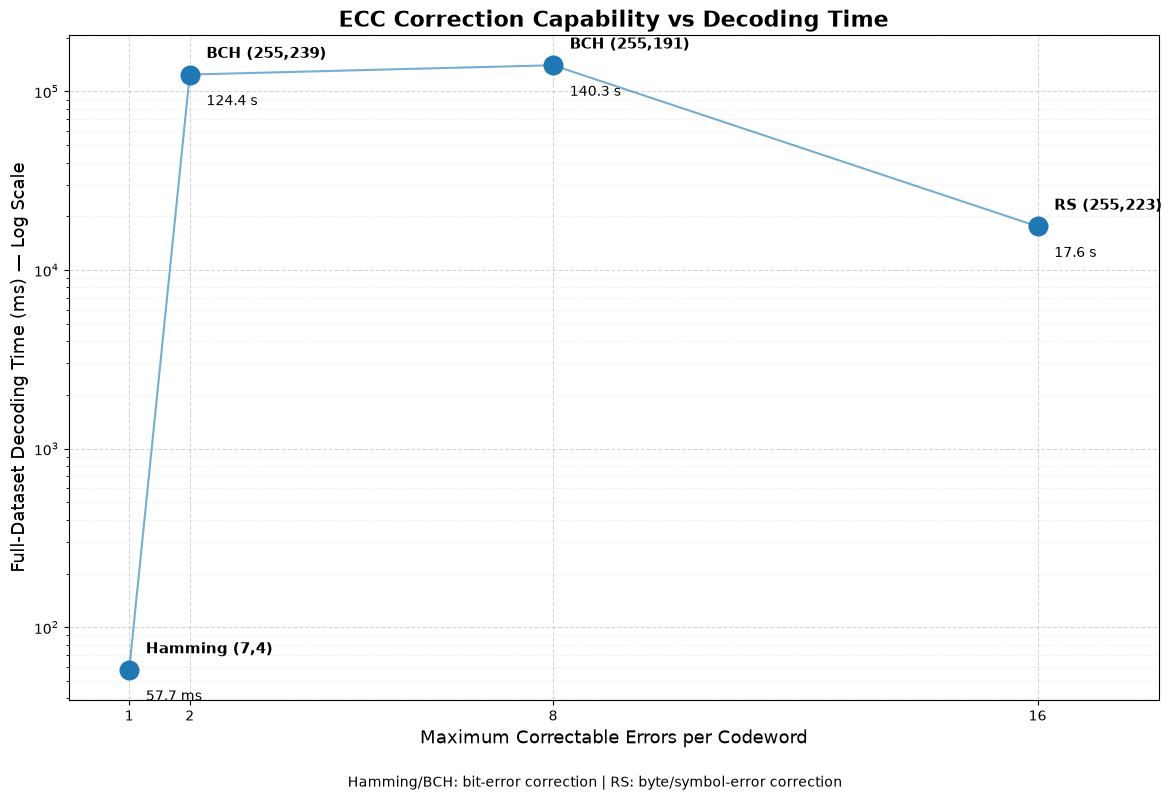

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# ECC PERFORMANCE COMPARISON
# ============================================================

ecc_names = [
    "Hamming (7,4)",
    "BCH (255,239)",
    "BCH (255,191)",
    "RS (255,223)"
]

# Maximum correction capability
# Hamming/BCH -> bit errors
# RS -> symbol (byte) errors
max_correctable = np.array([
    1,
    2,
    8,
    16
])

# Full-dataset decoding time in milliseconds
decode_time_ms = np.array([
    57.727113,
    124381.177,
    140251.119,
    17567.561
])


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(12, 8))

# Plot points
ax.scatter(
    max_correctable,
    decode_time_ms,
    s=180,
    zorder=3
)

# Connect points
ax.plot(
    max_correctable,
    decode_time_ms,
    linewidth=1.5,
    alpha=0.6
)


# ============================================================
# ANNOTATIONS
# ============================================================

for x, y, name in zip(
    max_correctable,
    decode_time_ms,
    ecc_names
):

    ax.annotate(
        name,
        xy=(x, y),
        xytext=(12, 12),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold"
    )


# ============================================================
# LOG SCALE
# ============================================================

ax.set_yscale("log")


# ============================================================
# LABELS
# ============================================================

ax.set_xlabel(
    "Maximum Correctable Errors per Codeword",
    fontsize=13
)

ax.set_ylabel(
    "Full-Dataset Decoding Time (ms) — Log Scale",
    fontsize=13
)

ax.set_title(
    "ECC Correction Capability vs Decoding Time",
    fontsize=16,
    fontweight="bold"
)


# ============================================================
# X AXIS
# ============================================================

ax.set_xticks(max_correctable)

ax.set_xlim(
    0,
    18
)


# ============================================================
# GRID
# ============================================================

ax.grid(
    True,
    which="major",
    linestyle="--",
    alpha=0.5
)

ax.grid(
    True,
    which="minor",
    linestyle=":",
    alpha=0.25
)


# ============================================================
# ADD TIME LABELS
# ============================================================

for x, y in zip(
    max_correctable,
    decode_time_ms
):

    if y < 1000:
        label = f"{y:.1f} ms"
    elif y < 10000:
        label = f"{y/1000:.2f} s"
    else:
        label = f"{y/1000:.1f} s"

    ax.annotate(
        label,
        xy=(x, y),
        xytext=(12, -22),
        textcoords="offset points",
        fontsize=10
    )


# ============================================================
# FOOTNOTE
# ============================================================

fig.text(
    0.5,
    0.01,
    "Hamming/BCH: bit-error correction | RS: byte/symbol-error correction",
    ha="center",
    fontsize=10
)


plt.tight_layout(
    rect=[0, 0.04, 1, 1]
)

plt.show()

trying to split rules into no of rpi and send via ap mitm and find ecc

splitting into 3

In [1]:
import numpy as np
import os

# ============================================================
# STEP 1: SPLIT RULES .NPY INTO 3 PARTS
# ============================================================

RULES_PATH = r"/home/<user>/iot_dataset/rules_bitpacked.npy"


# ------------------------------------------------------------
# Load rules
# ------------------------------------------------------------

rules = np.load(RULES_PATH)

print("============================================================")
print("              RULES.NPY 3-WAY SPLITTER")
print("============================================================")

print(f"Input file : {RULES_PATH}")
print(f"Shape      : {rules.shape}")
print(f"Dtype      : {rules.dtype}")
print(f"Total      : {rules.size:,}")
print()


# ------------------------------------------------------------
# Check that it can be divided into 3 equal parts
# ------------------------------------------------------------

if rules.shape[0] % 3 != 0:
    raise ValueError(
        f"Cannot split first dimension equally into 3. "
        f"First dimension = {rules.shape[0]}"
    )


# ------------------------------------------------------------
# Split along the FIRST dimension
# ------------------------------------------------------------

parts = np.array_split(rules, 3, axis=0)

output_dir = os.path.dirname(RULES_PATH)

for i, part in enumerate(parts):

    output_path = os.path.join(
        output_dir,
        f"rules_part{i}.npy"
    )

    np.save(output_path, part)

    print(
        f"Part {i}: "
        f"shape={part.shape}, "
        f"elements={part.size:,}, "
        f"file={output_path}"
    )


print()
print("============================================================")
print("SPLIT COMPLETE")
print("============================================================")

              RULES.NPY 3-WAY SPLITTER
Input file : /home/<user>/iot_dataset/rules_bitpacked.npy
Shape      : (6, 6000, 66)
Dtype      : uint8
Total      : 2,376,000

Part 0: shape=(2, 6000, 66), elements=792,000, file=/home/<user>/iot_dataset/rules_part0.npy
Part 1: shape=(2, 6000, 66), elements=792,000, file=/home/<user>/iot_dataset/rules_part1.npy
Part 2: shape=(2, 6000, 66), elements=792,000, file=/home/<user>/iot_dataset/rules_part2.npy

SPLIT COMPLETE


encoding the files

In [2]:
import numpy as np
import os

# ============================================================
# STEP 2: HAMMING(7,4) ENCODER FOR ALL 3 SPLIT FILES
# ============================================================

BASE_DIR = r"/home/<user>/iot_dataset"

INPUT_FILES = [
    os.path.join(BASE_DIR, "rules_part0.npy"),
    os.path.join(BASE_DIR, "rules_part1.npy"),
    os.path.join(BASE_DIR, "rules_part2.npy"),
]


# ============================================================
# HAMMING(7,4)
#
# Codeword:
#
# bit:    6 5 4 3 2 1 0
#         P1 P2 D1 P4 D2 D3 D4
#
# D1 D2 D3 D4 = input nibble
# ============================================================

def hamming74_encode_nibble(nibble):

    d1 = (nibble >> 3) & 1
    d2 = (nibble >> 2) & 1
    d3 = (nibble >> 1) & 1
    d4 = nibble & 1

    # Even parity
    p1 = d1 ^ d2 ^ d4
    p2 = d1 ^ d3 ^ d4
    p4 = d2 ^ d3 ^ d4

    codeword = (
        (p1 << 6) |
        (p2 << 5) |
        (d1 << 4) |
        (p4 << 3) |
        (d2 << 2) |
        (d3 << 1) |
        d4
    )

    return codeword


# ============================================================
# ENCODE ONE BYTE ARRAY
# ============================================================

def hamming_encode_bytes(data):

    output_bits = []

    for byte in data:

        # Upper nibble
        high = (byte >> 4) & 0x0F

        # Lower nibble
        low = byte & 0x0F

        cw1 = hamming74_encode_nibble(high)
        cw2 = hamming74_encode_nibble(low)

        # MSB first
        for bit in range(6, -1, -1):
            output_bits.append((cw1 >> bit) & 1)

        for bit in range(6, -1, -1):
            output_bits.append((cw2 >> bit) & 1)

    # Convert bits → bytes
    encoded = np.packbits(np.array(output_bits, dtype=np.uint8))

    return encoded


# ============================================================
# PROCESS ALL 3 FILES
# ============================================================

print("============================================================")
print("              HAMMING(7,4) ENCODER")
print("============================================================")

for part_id, input_file in enumerate(INPUT_FILES):

    print()
    print(f"Processing chunk {part_id}")
    print("--------------------------------------------")

    # --------------------------------------------------------
    # Load .npy
    # --------------------------------------------------------

    data = np.load(input_file)

    print(f"Input shape       : {data.shape}")
    print(f"Input dtype       : {data.dtype}")
    print(f"Input elements    : {data.size:,}")

    # --------------------------------------------------------
    # Convert to bytes
    # --------------------------------------------------------

    raw_bytes = data.tobytes()

    print(f"Input bytes       : {len(raw_bytes):,}")

    # --------------------------------------------------------
    # Hamming encode
    # --------------------------------------------------------

    encoded = hamming_encode_bytes(raw_bytes)

    print(f"Encoded bytes     : {len(encoded):,}")

    # --------------------------------------------------------
    # Save encoded stream
    # --------------------------------------------------------

    output_file = os.path.join(
        BASE_DIR,
        f"rules_part{part_id}_hamming.bin"
    )

    encoded.tofile(output_file)

    print(f"Output            : {output_file}")


print()
print("============================================================")
print("             ALL 3 CHUNKS ENCODED")
print("============================================================")

              HAMMING(7,4) ENCODER

Processing chunk 0
--------------------------------------------
Input shape       : (2, 6000, 66)
Input dtype       : uint8
Input elements    : 792,000
Input bytes       : 792,000
Encoded bytes     : 1,386,000
Output            : /home/<user>/iot_dataset/rules_part0_hamming.bin

Processing chunk 1
--------------------------------------------
Input shape       : (2, 6000, 66)
Input dtype       : uint8
Input elements    : 792,000
Input bytes       : 792,000
Encoded bytes     : 1,386,000
Output            : /home/<user>/iot_dataset/rules_part1_hamming.bin

Processing chunk 2
--------------------------------------------
Input shape       : (2, 6000, 66)
Input dtype       : uint8
Input elements    : 792,000
Input bytes       : 792,000
Encoded bytes     : 1,386,000
Output            : /home/<user>/iot_dataset/rules_part2_hamming.bin

             ALL 3 CHUNKS ENCODED


corrupting one file ,above files are rules_partnum

In [7]:
import numpy as np
import os

# ============================================================
# STEP 3B
# CORRUPT ONE CHUNK
# GUARANTEE MAXIMUM 1 ERROR PER HAMMING(7,4) CODEWORD
# ============================================================

BASE_DIR = r"/home/<user>/iot_dataset"

CORRUPT_CHUNK = 1

ERROR_RATE = 0.002       # 0.2%

INPUT_FILE = os.path.join(
    BASE_DIR,
    f"rules_part{CORRUPT_CHUNK}_hamming.bin"
)

OUTPUT_FILE = os.path.join(
    BASE_DIR,
    f"rules_part{CORRUPT_CHUNK}_hamming_corrupted.bin"
)

RANDOM_SEED = 42


# ============================================================
# LOAD ENCODED DATA
# ============================================================

data = np.fromfile(
    INPUT_FILE,
    dtype=np.uint8
)

total_bits = data.size * 8

# Number of bits we want to corrupt
requested_errors = int(
    total_bits * ERROR_RATE
)

# ============================================================
# HAMMING CODEWORD COUNT
#
# Every codeword = 7 bits
# ============================================================

total_codewords = total_bits // 7

# We cannot corrupt more codewords than exist
num_errors = min(
    requested_errors,
    total_codewords
)


print("============================================================")
print("     SINGLE-ERROR-PER-CODEWORD HAMMING CORRUPTION")
print("============================================================")

print(f"Input file          : {INPUT_FILE}")
print(f"Encoded bytes       : {data.size:,}")
print(f"Encoded bits        : {total_bits:,}")
print(f"Total codewords     : {total_codewords:,}")
print(f"Requested errors    : {requested_errors:,}")
print(f"Actual errors       : {num_errors:,}")
print(f"Error rate          : {ERROR_RATE * 100:.2f}%")


# ============================================================
# SELECT UNIQUE CODEWORDS
#
# Each selected codeword gets EXACTLY ONE flipped bit.
# ============================================================

rng = np.random.default_rng(
    RANDOM_SEED
)

selected_codewords = rng.choice(
    total_codewords,
    size=num_errors,
    replace=False
)


# ============================================================
# COPY ORIGINAL
# ============================================================

corrupted = data.copy()


# ============================================================
# FLIP ONE RANDOM BIT INSIDE EACH SELECTED CODEWORD
# ============================================================

for codeword_index in selected_codewords:

    # Start of this 7-bit codeword
    codeword_start = codeword_index * 7

    # Pick one of the 7 bits
    bit_inside_codeword = rng.integers(
        0,
        7
    )

    bit_position = (
        codeword_start +
        bit_inside_codeword
    )

    byte_index = bit_position // 8

    bit_index = 7 - (
        bit_position % 8
    )

    corrupted[byte_index] ^= (
        1 << bit_index
    )


# ============================================================
# SAVE
# ============================================================

corrupted.tofile(
    OUTPUT_FILE
)


# ============================================================
# RESULT
# ============================================================

print()
print(f"Corrupted chunk     : {CORRUPT_CHUNK}")
print(f"Bits flipped        : {num_errors:,}")
print(f"Output file         : {OUTPUT_FILE}")

print()
print("============================================================")
print("             CORRUPTION COMPLETE")
print("============================================================")

     SINGLE-ERROR-PER-CODEWORD HAMMING CORRUPTION
Input file          : /home/<user>/iot_dataset/rules_part1_hamming.bin
Encoded bytes       : 1,386,000
Encoded bits        : 11,088,000
Total codewords     : 1,584,000
Requested errors    : 22,176
Actual errors       : 22,176
Error rate          : 0.20%

Corrupted chunk     : 1
Bits flipped        : 22,176
Output file         : /home/<user>/iot_dataset/rules_part1_hamming_corrupted.bin

             CORRUPTION COMPLETE


decoder

In [8]:
import numpy as np
import os

# ============================================================
# HAMMING(7,4) DECODER
# 3 CHUNKS
# ============================================================

BASE_DIR = r"/home/<user>/iot_dataset"

# ------------------------------------------------------------
# Encoded files
# ------------------------------------------------------------

ENCODED_FILES = [
    os.path.join(BASE_DIR, "rules_part0_hamming.bin"),
    os.path.join(BASE_DIR, "rules_part1_hamming_corrupted.bin"),
    os.path.join(BASE_DIR, "rules_part2_hamming.bin"),
]

# ------------------------------------------------------------
# ORIGINAL COMPLETE RULES
# Used ONLY for final PC verification
# ------------------------------------------------------------

ORIGINAL_RULES = r"/home/<user>/iot_dataset/rules_bitpacked.npy"

# ------------------------------------------------------------
# Final reconstructed output
# ------------------------------------------------------------

CORRECTED_OUTPUT = os.path.join(
    BASE_DIR,
    "rules_corrected.bin"
)


# ============================================================
# HAMMING(7,4) DECODE ONE CODEWORD
#
# Codeword:
#
# bit:    6 5 4 3 2 1 0
#         P1 P2 D1 P4 D2 D3 D4
# ============================================================

def decode_codeword(cw):

    # Extract bits

    p1 = (cw >> 6) & 1
    p2 = (cw >> 5) & 1
    d1 = (cw >> 4) & 1
    p4 = (cw >> 3) & 1
    d2 = (cw >> 2) & 1
    d3 = (cw >> 1) & 1
    d4 = cw & 1

    # --------------------------------------------------------
    # Syndrome
    # --------------------------------------------------------

    s1 = p1 ^ d1 ^ d2 ^ d4
    s2 = p2 ^ d1 ^ d3 ^ d4
    s4 = p4 ^ d2 ^ d3 ^ d4

    syndrome = (
        s1 |
        (s2 << 1) |
        (s4 << 2)
    )

    corrected = False

    # --------------------------------------------------------
    # Single-bit correction
    # --------------------------------------------------------

    if syndrome != 0:

        # Hamming position:
        #
        # 1 -> bit 6
        # 2 -> bit 5
        # 3 -> bit 4
        # 4 -> bit 3
        # 5 -> bit 2
        # 6 -> bit 1
        # 7 -> bit 0

        bit_to_flip = 7 - syndrome

        cw ^= (1 << bit_to_flip)

        corrected = True

    # --------------------------------------------------------
    # Extract corrected data
    # --------------------------------------------------------

    d1 = (cw >> 4) & 1
    d2 = (cw >> 2) & 1
    d3 = (cw >> 1) & 1
    d4 = cw & 1

    nibble = (
        (d1 << 3) |
        (d2 << 2) |
        (d3 << 1) |
        d4
    )

    return nibble, syndrome, corrected


# ============================================================
# DECODE ONE CHUNK
# ============================================================

def decode_chunk(encoded_file):

    encoded = np.fromfile(
        encoded_file,
        dtype=np.uint8
    )

    total_bits = encoded.size * 8

    if total_bits % 14 != 0:
        raise ValueError(
            f"Invalid encoded size: {encoded_file}"
        )

    original_bytes = total_bits // 14

    decoded = np.empty(
        original_bytes,
        dtype=np.uint8
    )

    error_codewords = 0
    corrected_codewords = 0

    bit_position = 0

    # ========================================================
    # PROCESS EVERY ORIGINAL BYTE
    # ========================================================

    for byte_index in range(original_bytes):

        # ----------------------------------------------------
        # First 7-bit codeword
        # ----------------------------------------------------

        cw1 = 0

        for _ in range(7):

            byte_index_encoded = bit_position // 8
            bit_index = 7 - (bit_position % 8)

            bit = (
                encoded[byte_index_encoded]
                >> bit_index
            ) & 1

            cw1 = (cw1 << 1) | bit

            bit_position += 1

        # ----------------------------------------------------
        # Second 7-bit codeword
        # ----------------------------------------------------

        cw2 = 0

        for _ in range(7):

            byte_index_encoded = bit_position // 8
            bit_index = 7 - (bit_position % 8)

            bit = (
                encoded[byte_index_encoded]
                >> bit_index
            ) & 1

            cw2 = (cw2 << 1) | bit

            bit_position += 1

        # ----------------------------------------------------
        # Decode
        # ----------------------------------------------------

        high, syndrome1, corrected1 = \
            decode_codeword(cw1)

        low, syndrome2, corrected2 = \
            decode_codeword(cw2)

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        if syndrome1 != 0:
            error_codewords += 1

        if syndrome2 != 0:
            error_codewords += 1

        if corrected1:
            corrected_codewords += 1

        if corrected2:
            corrected_codewords += 1

        # ----------------------------------------------------
        # Reconstruct original byte
        # ----------------------------------------------------

        decoded[byte_index] = (
            (high << 4) | low
        )

    return (
        decoded,
        error_codewords,
        corrected_codewords
    )


# ============================================================
# START
# ============================================================

print()
print("============================================================")
print("             3-CHUNK HAMMING(7,4) DECODER")
print("============================================================")


decoded_chunks = []

total_errors = 0
total_corrections = 0


# ============================================================
# DECODE ALL THREE CHUNKS
# ============================================================

for chunk_id in range(3):

    encoded_file = ENCODED_FILES[chunk_id]

    print()
    print("------------------------------------------------------------")
    print(f"CHUNK {chunk_id}")
    print("------------------------------------------------------------")

    decoded, errors, corrections = \
        decode_chunk(encoded_file)

    decoded_chunks.append(decoded)

    total_errors += errors
    total_corrections += corrections

    print(
        f"Encoded file       : "
        f"{os.path.basename(encoded_file)}"
    )

    print(
        f"Encoded bytes      : "
        f"{os.path.getsize(encoded_file):,}"
    )

    print(
        f"Decoded bytes      : "
        f"{decoded.size:,}"
    )

    print(
        f"Error codewords    : "
        f"{errors:,}"
    )

    print(
        f"Corrections        : "
        f"{corrections:,}"
    )

    if errors == 0:

        print("Status             : CLEAN")
        print("Action             : DIRECT → INFERENCE")

    else:

        print("Status             : ERROR DETECTED")
        print("Action             : ECC CORRECTION → INFERENCE")


# ============================================================
# RECONSTRUCT COMPLETE RULE FILE
# ============================================================

print()
print("============================================================")
print("              RECONSTRUCTING COMPLETE RULES")
print("============================================================")

corrected_rules = np.concatenate(
    decoded_chunks
)

corrected_rules.tofile(
    CORRECTED_OUTPUT
)

print(
    f"Total corrected bytes : "
    f"{corrected_rules.size:,}"
)

print(
    f"Total error codewords : "
    f"{total_errors:,}"
)

print(
    f"Total corrections     : "
    f"{total_corrections:,}"
)

print(
    f"Output                : "
    f"{CORRECTED_OUTPUT}"
)


# ============================================================
# FINAL VERIFICATION
#
# Compare reconstructed rules against ORIGINAL rules.npy
# ============================================================

print()
print("============================================================")
print("              FINAL COMPLETE VERIFICATION")
print("============================================================")

original_array = np.load(
    ORIGINAL_RULES
)

original_bytes = np.frombuffer(
    original_array.tobytes(),
    dtype=np.uint8
)

print(
    f"Original bytes        : "
    f"{original_bytes.size:,}"
)

print(
    f"Corrected bytes       : "
    f"{corrected_rules.size:,}"
)


# ------------------------------------------------------------
# Size check
# ------------------------------------------------------------

if original_bytes.size != corrected_rules.size:

    print()
    print("RESULT                : FAIL")
    print("Reason                : SIZE MISMATCH")

else:

    # --------------------------------------------------------
    # Byte-by-byte comparison
    # --------------------------------------------------------

    mismatch_mask = (
        original_bytes != corrected_rules
    )

    mismatch_count = np.count_nonzero(
        mismatch_mask
    )

    print(
        f"Mismatched bytes     : "
        f"{mismatch_count:,}"
    )

    if mismatch_count == 0:

        print()
        print("RESULT                : PASS")
        print("All rules were correctly restored.")

    else:

        print()
        print("RESULT                : FAIL")
        print(
            f"{mismatch_count:,} bytes "
            f"could not be restored."
        )


# ============================================================
# FINAL
# ============================================================

print()
print("============================================================")
print("                    TEST COMPLETE")
print("============================================================")


             3-CHUNK HAMMING(7,4) DECODER

------------------------------------------------------------
CHUNK 0
------------------------------------------------------------
Encoded file       : rules_part0_hamming.bin
Encoded bytes      : 1,386,000
Decoded bytes      : 792,000
Error codewords    : 0
Corrections        : 0
Status             : CLEAN
Action             : DIRECT → INFERENCE

------------------------------------------------------------
CHUNK 1
------------------------------------------------------------
Encoded file       : rules_part1_hamming_corrupted.bin
Encoded bytes      : 1,386,000
Decoded bytes      : 792,000
Error codewords    : 22,176
Corrections        : 22,176
Status             : ERROR DETECTED
Action             : ECC CORRECTION → INFERENCE

------------------------------------------------------------
CHUNK 2
------------------------------------------------------------
Encoded file       : rules_part2_hamming.bin
Encoded bytes      : 1,386,000
Decoded bytes  

In [14]:
import numpy as np
import os

# ============================================================
# FULL ECC + TM INFERENCE TEST
#
# Pipeline:
#
# rules_bitpacked.npy
#        |
#        +----------------------+
#        |                      |
#        v                      v
# ORIGINAL RULES          Hamming ECC
#                               |
#                               v
#                       rules_corrected.bin
#                               |
#                               v
#                    compare original/ECC
#                               |
#                               v
#                          INFERENCE
#                               |
#                    +----------+----------+
#                    |                     |
#               Original rules       ECC rules
#                    |                     |
#                    +----------+----------+
#                               |
#                               v
#                         Compare outputs
#                               |
#                               v
#                       Compare with GT
# ============================================================


# ============================================================
# PATHS
# ============================================================

BASE_DIR = r"/home/<user>/iot_dataset"

# Original bit-packed rules
ORIGINAL_RULES = os.path.join(
    BASE_DIR,
    "rules_bitpacked.npy"
)

# Output from Hamming decoder
CORRECTED_RULES = os.path.join(
    BASE_DIR,
    "rules_corrected.bin"
)

# TM weights
WEIGHTS_FILE = r"/home/<user>/iot_dataset/rpi_tm_model/weights.npy"

# Test input
INPUT_FILE = r"/home/<user>/iot_dataset/rpi_50_test/X_50.npy"

# Ground truth
GROUND_TRUTH_FILE = r"/home/<user>/iot_dataset/rpi_50_test/y_50_actual.npy"


# ============================================================
# MODEL PARAMETERS
# ============================================================

NUM_CLASSES = 6
CLAUSES_PER_CLASS = 6000

INPUT_FEATURES = 263
NUM_LITERALS = 526

RULE_BYTES = 66


# ============================================================
# LOAD FILES
# ============================================================

print()
print("============================================================")
print("             ECC + TM INFERENCE TEST")
print("============================================================")

rules_original = np.load(
    ORIGINAL_RULES
)

weights = np.load(
    WEIGHTS_FILE
)

X = np.load(
    INPUT_FILE
)

y_true = np.load(
    GROUND_TRUTH_FILE
)


# ============================================================
# PRINT MODEL INFORMATION
# ============================================================

print()
print("MODEL INFORMATION")
print("------------------------------------------------------------")

print(
    f"Original rules shape : {rules_original.shape}"
)

print(
    f"Original rules dtype : {rules_original.dtype}"
)

print(
    f"Weights shape        : {weights.shape}"
)

print(
    f"Weights dtype        : {weights.dtype}"
)

print(
    f"Input shape          : {X.shape}"
)

print(
    f"Ground truth shape   : {y_true.shape}"
)


# ============================================================
# CHECK RULE SHAPE
# ============================================================

if rules_original.shape != (
    NUM_CLASSES,
    CLAUSES_PER_CLASS,
    RULE_BYTES
):

    raise ValueError(
        "Unexpected bit-packed rule shape!\n"
        f"Expected: "
        f"({NUM_CLASSES}, "
        f"{CLAUSES_PER_CLASS}, "
        f"{RULE_BYTES})\n"
        f"Got: {rules_original.shape}"
    )


# ============================================================
# CHECK WEIGHTS
# ============================================================

if weights.shape != (
    NUM_CLASSES,
    CLAUSES_PER_CLASS
):

    raise ValueError(
        "Unexpected weight shape!\n"
        f"Expected: "
        f"({NUM_CLASSES}, {CLAUSES_PER_CLASS})\n"
        f"Got: {weights.shape}"
    )


# ============================================================
# LOAD ECC-CORRECTED RULES
#
# rules_corrected.bin is:
#
#     6 × 6000 × 66
#
# ============================================================

corrected_bytes = np.fromfile(
    CORRECTED_RULES,
    dtype=np.uint8
)


expected_bytes = (
    NUM_CLASSES *
    CLAUSES_PER_CLASS *
    RULE_BYTES
)


print()
print("ECC RULE FILE")
print("------------------------------------------------------------")

print(
    f"Expected bytes      : {expected_bytes:,}"
)

print(
    f"Corrected file bytes : {corrected_bytes.size:,}"
)


if corrected_bytes.size != expected_bytes:

    raise ValueError(
        "Corrected rules file size is wrong!\n"
        f"Expected: {expected_bytes:,}\n"
        f"Got:      {corrected_bytes.size:,}"
    )


# ============================================================
# RESHAPE ECC RULES
# ============================================================

rules_corrected = corrected_bytes.reshape(
    NUM_CLASSES,
    CLAUSES_PER_CLASS,
    RULE_BYTES
)


print(
    f"Corrected shape     : {rules_corrected.shape}"
)


# ============================================================
# RULE-LEVEL VERIFICATION
#
# Compare the complete bit-packed rule files.
# ============================================================

print()
print("============================================================")
print("                ECC RULE VERIFICATION")
print("============================================================")


rule_difference = (
    rules_original != rules_corrected
)

mismatched_bytes = np.count_nonzero(
    rule_difference
)

print(
    f"Original bytes      : "
    f"{rules_original.size:,}"
)

print(
    f"Corrected bytes     : "
    f"{rules_corrected.size:,}"
)

print(
    f"Mismatched bytes    : "
    f"{mismatched_bytes:,}"
)


if mismatched_bytes == 0:

    print()
    print("RULE VERIFICATION   : PASS")

else:

    print()
    print("RULE VERIFICATION   : FAIL")


# ============================================================
# INPUT PACKING
#
# 263 input features
#
# Positive literals:
#     x[0 ... 262]
#
# Negative literals:
#     !x[0 ... 262]
#
# Total:
#     526 literals
#
# 526 bits -> 66 bytes
# ============================================================

def make_input_literals(sample):

    sample = np.asarray(
        sample,
        dtype=np.uint8
    ).reshape(-1)

    if sample.size != INPUT_FEATURES:

        raise ValueError(
            f"Expected {INPUT_FEATURES} input features, "
            f"got {sample.size}"
        )

    # Make sure input is binary
    if not np.all(
        (sample == 0) |
        (sample == 1)
    ):

        raise ValueError(
            "Input contains values other than 0/1"
        )

    positive = sample

    negative = 1 - sample

    literals = np.concatenate(
        (
            positive,
            negative
        )
    )

    return literals


# ============================================================
# PACK INPUT INTO 66 BYTES
#
# IMPORTANT:
# bitorder='little'
#
# This matches the bit-packed rule representation used
# throughout this experiment.
# ============================================================

def pack_input(sample):

    literals = make_input_literals(
        sample
    )

    packed = np.packbits(
        literals,
        bitorder="little"
    )

    if packed.size != RULE_BYTES:

        raise ValueError(
            f"Packed input should contain "
            f"{RULE_BYTES} bytes, "
            f"got {packed.size}"
        )

    # 526 valid bits.
    #
    # 66 bytes = 528 bits.
    #
    # Last 2 bits are padding.
    #
    packed[-1] &= 0x3F

    return packed


# ============================================================
# TM INFERENCE USING BIT-PACKED RULES
#
# rules shape:
#
#     (6, 6000, 66)
#
# input:
#
#     (66,)
#
# weights:
#
#     (6, 6000)
#
# ============================================================

def tm_predict(
    sample,
    packed_rules,
    weights
):

    packed_input = pack_input(
        sample
    )

    # --------------------------------------------------------
    # A clause is satisfied if every required literal
    # contained in the clause is also present in the input.
    #
    # required = clause & ~input
    #
    # If required == 0 for every byte:
    #
    #     clause is satisfied
    # --------------------------------------------------------

    required_bits = (
        packed_rules &
        np.bitwise_not(
            packed_input
        )
    )

    clause_outputs = np.all(
        required_bits == 0,
        axis=2
    )

    # --------------------------------------------------------
    # Disable completely empty clauses.
    # --------------------------------------------------------

    clause_nonempty = np.any(
        packed_rules != 0,
        axis=2
    )

    clause_outputs &= clause_nonempty

    # --------------------------------------------------------
    # Apply weights
    #
    # clause_outputs:
    #
    #     (6, 6000)
    #
    # weights:
    #
    #     (6, 6000)
    #
    # result:
    #
    #     (6,)
    # --------------------------------------------------------

    scores = np.sum(
        weights *
        clause_outputs,
        axis=1
    )

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    prediction = int(
        np.argmax(scores)
    )

    return prediction, scores


# ============================================================
# TEST ONE SAMPLE FIRST
# ============================================================

print()
print("============================================================")
print("                 SINGLE SAMPLE TEST")
print("============================================================")

test_sample = X[0]

pred_original, score_original = tm_predict(
    test_sample,
    rules_original,
    weights
)

pred_corrected, score_corrected = tm_predict(
    test_sample,
    rules_corrected,
    weights
)

print(
    f"Ground truth       : {int(y_true[0])}"
)

print(
    f"Original prediction: {pred_original}"
)

print(
    f"ECC prediction     : {pred_corrected}"
)

print(
    f"Original scores    : {score_original}"
)

print(
    f"ECC scores         : {score_corrected}"
)

print(
    f"Prediction match   : "
    f"{'YES' if pred_original == pred_corrected else 'NO'}"
)

print(
    f"Original vs GT     : "
    f"{'CORRECT' if pred_original == y_true[0] else 'WRONG'}"
)

print(
    f"ECC vs GT          : "
    f"{'CORRECT' if pred_corrected == y_true[0] else 'WRONG'}"
)


# ============================================================
# FULL DATASET INFERENCE
# ============================================================

print()
print("============================================================")
print("              FULL INFERENCE TEST")
print("============================================================")


num_samples = len(X)

original_predictions = np.empty(
    num_samples,
    dtype=np.int32
)

corrected_predictions = np.empty(
    num_samples,
    dtype=np.int32
)

original_scores = np.empty(
    (num_samples, NUM_CLASSES),
    dtype=np.int64
)

corrected_scores = np.empty(
    (num_samples, NUM_CLASSES),
    dtype=np.int64
)


# ============================================================
# RUN INFERENCE
# ============================================================

for i in range(num_samples):

    # --------------------------------------------------------
    # ORIGINAL RULES
    # --------------------------------------------------------

    pred_original, scores_original = tm_predict(
        X[i],
        rules_original,
        weights
    )

    # --------------------------------------------------------
    # ECC-CORRECTED RULES
    # --------------------------------------------------------

    pred_corrected, scores_corrected = tm_predict(
        X[i],
        rules_corrected,
        weights
    )

    original_predictions[i] = (
        pred_original
    )

    corrected_predictions[i] = (
        pred_corrected
    )

    original_scores[i] = (
        scores_original
    )

    corrected_scores[i] = (
        scores_corrected
    )


# ============================================================
# PREDICTION COMPARISON
# ============================================================

prediction_match = (
    original_predictions ==
    corrected_predictions
)

prediction_mismatches = np.count_nonzero(
    ~prediction_match
)


# ============================================================
# GROUND TRUTH
# ============================================================

original_gt_match = (
    original_predictions ==
    y_true
)

corrected_gt_match = (
    corrected_predictions ==
    y_true
)

original_correct = np.count_nonzero(
    original_gt_match
)

corrected_correct = np.count_nonzero(
    corrected_gt_match
)


# ============================================================
# SCORE COMPARISON
# ============================================================

scores_identical = np.array_equal(
    original_scores,
    corrected_scores
)


# ============================================================
# PRINT PER-SAMPLE RESULTS
# ============================================================

print()

print(
    f"{'Sample':<10}"
    f"{'GT':<8}"
    f"{'Original':<12}"
    f"{'ECC':<8}"
    f"{'Match':<8}"
)

print(
    "------------------------------------------------------------"
)

for i in range(num_samples):

    match = (
        original_predictions[i] ==
        corrected_predictions[i]
    )

    print(
        f"{i:<10}"
        f"{int(y_true[i]):<8}"
        f"{original_predictions[i]:<12}"
        f"{corrected_predictions[i]:<8}"
        f"{'YES' if match else 'NO':<8}"
    )


# ============================================================
# FINAL RESULTS
# ============================================================

print()
print("============================================================")
print("                    FINAL RESULTS")
print("============================================================")

print()
print(
    f"Rule mismatched bytes       : "
    f"{mismatched_bytes:,}"
)

print(
    f"Prediction mismatches       : "
    f"{prediction_mismatches:,}"
)

print()

print(
    f"Original correct            : "
    f"{original_correct}/{num_samples}"
)

print(
    f"ECC correct                 : "
    f"{corrected_correct}/{num_samples}"
)

print()

print(
    f"Original accuracy           : "
    f"{100.0 * original_correct / num_samples:.2f}%"
)

print(
    f"ECC accuracy                : "
    f"{100.0 * corrected_correct / num_samples:.2f}%"
)

print()

print(
    f"Scores identical            : "
    f"{'YES' if scores_identical else 'NO'}"
)


# ============================================================
# SCORE DIFFERENCE
# ============================================================

if not scores_identical:

    score_difference = np.abs(
        original_scores -
        corrected_scores
    )

    max_score_difference = np.max(
        score_difference
    )

    total_score_differences = np.count_nonzero(
        score_difference
    )

    print(
        f"Different score values      : "
        f"{total_score_differences:,}"
    )

    print(
        f"Maximum score difference   : "
        f"{max_score_difference}"
    )


# ============================================================
# FINAL PASS / FAIL
# ============================================================

print()
print("============================================================")

if (
    mismatched_bytes == 0 and
    prediction_mismatches == 0 and
    scores_identical
):

    print("ECC + INFERENCE RESULT : PASS")

else:

    print("ECC + INFERENCE RESULT : CHECK")

print("============================================================")


             ECC + TM INFERENCE TEST

MODEL INFORMATION
------------------------------------------------------------
Original rules shape : (6, 6000, 66)
Original rules dtype : uint8
Weights shape        : (6, 6000)
Weights dtype        : int8
Input shape          : (50, 263)
Ground truth shape   : (50,)

ECC RULE FILE
------------------------------------------------------------
Expected bytes      : 2,376,000
Corrected file bytes : 2,376,000
Corrected shape     : (6, 6000, 66)

                ECC RULE VERIFICATION
Original bytes      : 2,376,000
Corrected bytes     : 2,376,000
Mismatched bytes    : 0

RULE VERIFICATION   : PASS

                 SINGLE SAMPLE TEST
Ground truth       : 1
Original prediction: 1
ECC prediction     : 1
Original scores    : [ -726  2590  -553  -856 -2769 -2759]
ECC scores         : [ -726  2590  -553  -856 -2769 -2759]
Prediction match   : YES
Original vs GT     : CORRECT
ECC vs GT          : CORRECT

              FULL INFERENCE TEST

Sample    GT      

pythn finished coming to edge converting to .bin and storing

In [15]:
import os
import shutil

# ============================================================
# PATHS
# ============================================================

SOURCE_DIR = r"/home/<user>/iot_dataset"
DEST_DIR   = r"/home/<user>/rpi_hamming_bin_files"

os.makedirs(DEST_DIR, exist_ok=True)

# ============================================================
# COPY THE 3 HAMMING ENCODED FILES
# ============================================================

for i in range(3):

    src = os.path.join(
        SOURCE_DIR,
        f"rules_part{i}_hamming.bin"
    )

    dst = os.path.join(
        DEST_DIR,
        f"rules_part{i}_hamming.bin"
    )

    if not os.path.exists(src):
        raise FileNotFoundError(f"Missing file: {src}")

    shutil.copy2(src, dst)

    size = os.path.getsize(dst)

    print(f"Copied: rules_part{i}_hamming.bin")
    print(f"Size  : {size:,} bytes")
    print()

# ============================================================
# FINAL CHECK
# ============================================================

print("============================================")
print("RPi HAMMING FILES READY")
print("============================================")

for i in range(3):

    path = os.path.join(
        DEST_DIR,
        f"rules_part{i}_hamming.bin"
    )

    size = os.path.getsize(path)

    print(f"rules_part{i}_hamming.bin : {size:,} bytes")

print("============================================")

Copied: rules_part0_hamming.bin
Size  : 1,386,000 bytes

Copied: rules_part1_hamming.bin
Size  : 1,386,000 bytes

Copied: rules_part2_hamming.bin
Size  : 1,386,000 bytes

RPi HAMMING FILES READY
rules_part0_hamming.bin : 1,386,000 bytes
rules_part1_hamming.bin : 1,386,000 bytes
rules_part2_hamming.bin : 1,386,000 bytes


encoded and correctly packed

In [5]:
import numpy as np
import os
import struct


# ============================================================
#              CORRECTED GROUPED HAMMING GENERATOR
# ============================================================
#
# Model:
#
#   rules_bitpacked.npy : (6, 6000, 66), uint8
#   weights.npy         : (6, 6000), int8
#
# Transmission:
#
#   class + weight + sequence + rules
#
# Packet:
#
#   4-byte application header
#   792 bytes rule data
#   -------------------
#   796 raw bytes
#
# Hamming(7,4):
#
#   796 raw bytes -> 1393 encoded bytes
#
# Each packet contains:
#
#   12 complete rules
#
# No rule is split across packets.
#
# ============================================================


# ============================================================
#                         PATHS
# ============================================================

BASE_DIR = r"/home/<user>/iot_dataset"

RULES_FILE = os.path.join(
    BASE_DIR,
    "rules_bitpacked.npy"
)

WEIGHTS_FILE = os.path.join(
    BASE_DIR,
    "rpi_tm_model",
    "weights.npy"
)

OUTPUT_DIR = r"/home/<user>/rpi_grouped_hamming"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
#                    MODEL PARAMETERS
# ============================================================

NUM_CLASSES = 6
CLAUSES_PER_CLASS = 6000

RULE_BYTES = 66

# ============================================================
#                    PACKET PARAMETERS
# ============================================================

HEADER_BYTES = 4

RULES_PER_PACKET = 12

RULE_DATA_BYTES = (
    RULES_PER_PACKET *
    RULE_BYTES
)

RAW_PACKET_BYTES = (
    HEADER_BYTES +
    RULE_DATA_BYTES
)

# ------------------------------------------------------------
# Hamming(7,4):
#
# Every input byte:
#     8 bits
#
# Two nibbles:
#     2 × 7 bits
#
# Therefore:
#
#     encoded bytes = raw_bytes × 14 / 8
#
# ------------------------------------------------------------

ENCODED_PACKET_BYTES = (
    RAW_PACKET_BYTES * 14 // 8
)

# ------------------------------------------------------------
# Number of packets per group:
#
# 6000 rules / 12 rules
# = 500 packets
#
# But each weight group contains 3000 rules:
#
# 3000 / 12 = 250 packets
# ------------------------------------------------------------

RULES_PER_WEIGHT_GROUP = (
    CLAUSES_PER_CLASS // 2
)

PACKETS_PER_GROUP = (
    RULES_PER_WEIGHT_GROUP //
    RULES_PER_PACKET
)

PACKETS_PER_PART = (
    2 * 2 * PACKETS_PER_GROUP
)


# ============================================================
#                       SANITY CHECKS
# ============================================================

assert (
    CLAUSES_PER_CLASS % 2 == 0
)

assert (
    RULES_PER_WEIGHT_GROUP %
    RULES_PER_PACKET == 0
)

assert (
    RAW_PACKET_BYTES * 14 % 8 == 0
)

assert (
    ENCODED_PACKET_BYTES == 1393
)

assert (
    RULE_DATA_BYTES == 792
)


# ============================================================
#                    HAMMING ENCODER
# ============================================================

def hamming_encode_nibble(nibble):
    """
    Hamming(7,4)

    Codeword layout:

        P1 P2 D1 P4 D2 D3 D4

    Data bits are taken LSB first.
    """

    d1 = (nibble >> 0) & 1
    d2 = (nibble >> 1) & 1
    d3 = (nibble >> 2) & 1
    d4 = (nibble >> 3) & 1

    # Even parity

    p1 = d1 ^ d2 ^ d4
    p2 = d1 ^ d3 ^ d4
    p4 = d2 ^ d3 ^ d4

    return np.array(
        [
            p1,
            p2,
            d1,
            p4,
            d2,
            d3,
            d4
        ],
        dtype=np.uint8
    )


def hamming_encode_bytes(data):
    """
    Encode arbitrary bytes using Hamming(7,4).

    Each byte:
        high nibble -> 7 bits
        low nibble  -> 7 bits

    Total:
        14 encoded bits / input byte
    """

    data = np.frombuffer(
        data,
        dtype=np.uint8
    )

    nibbles = np.empty(
        data.size * 2,
        dtype=np.uint8
    )

    # High nibble
    nibbles[0::2] = (
        data >> 4
    ) & 0x0F

    # Low nibble
    nibbles[1::2] = (
        data & 0x0F
    )

    # --------------------------------------------------------
    # Generate 7-bit Hamming codewords
    # --------------------------------------------------------

    encoded_bits = np.empty(
        nibbles.size * 7,
        dtype=np.uint8
    )

    for i, nibble in enumerate(
        nibbles
    ):

        encoded_bits[
            i * 7:
            (i + 1) * 7
        ] = hamming_encode_nibble(
            int(nibble)
        )

    # --------------------------------------------------------
    # 7 bits × number of codewords
    # must produce an integer number of bytes.
    # --------------------------------------------------------

    encoded = np.packbits(
        encoded_bits,
        bitorder="big"
    )

    return encoded.tobytes()


# ============================================================
#                    PACKET HEADER
# ============================================================
#
# BYTE 0:
#
#     bits 7-4 = weight field
#     bits 3-0 = class ID
#
# BYTE 1:
#     sequence low byte
#
# BYTE 2:
#     sequence high byte
#
# BYTE 3:
#     flags/reserved
#
# ============================================================

def make_header(
    class_id,
    weight,
    sequence
):

    if not (
        0 <= class_id <= 15
    ):

        raise ValueError(
            f"Invalid class ID: {class_id}"
        )

    if weight not in (-1, +1):

        raise ValueError(
            f"Invalid weight: {weight}"
        )

    if not (
        0 <= sequence <= 65535
    ):

        raise ValueError(
            f"Sequence out of range: {sequence}"
        )

    # --------------------------------------------------------
    # Weight encoding
    #
    # 0 = -1
    # 1 = +1
    #
    # Stored in upper nibble.
    # --------------------------------------------------------

    if weight == -1:

        weight_field = 0

    else:

        weight_field = 1

    byte0 = (
        (weight_field << 4) |
        class_id
    )

    # --------------------------------------------------------
    # Sequence number
    # --------------------------------------------------------

    header = struct.pack(
        "<BHB",
        byte0,
        sequence,
        0
    )

    assert len(header) == 4

    return header


# ============================================================
#                BUILD ONE PACKET
# ============================================================

def make_packet(
    class_id,
    weight,
    sequence,
    rules
):

    rules = np.asarray(
        rules,
        dtype=np.uint8
    )

    # --------------------------------------------------------
    # Exactly 12 complete rules
    # --------------------------------------------------------

    if rules.shape != (
        RULES_PER_PACKET,
        RULE_BYTES
    ):

        raise ValueError(
            "Invalid rule block shape: "
            f"{rules.shape}. "
            f"Expected "
            f"({RULES_PER_PACKET}, "
            f"{RULE_BYTES})."
        )

    header = make_header(
        class_id,
        weight,
        sequence
    )

    rule_bytes = rules.tobytes()

    assert len(rule_bytes) == (
        RULE_DATA_BYTES
    )

    raw_packet = (
        header +
        rule_bytes
    )

    assert len(raw_packet) == (
        RAW_PACKET_BYTES
    )

    encoded_packet = hamming_encode_bytes(
        raw_packet
    )

    assert len(encoded_packet) == (
        ENCODED_PACKET_BYTES
    )

    return encoded_packet


# ============================================================
#              GENERATE ONE PART FILE
# ============================================================

def generate_part(
    part_id,
    class_ids,
    rules,
    weights
):

    output_file = os.path.join(
        OUTPUT_DIR,
        f"rules_part{part_id}_hamming.bin"
    )

    print()
    print(
        "============================================================"
    )

    print(
        f"GENERATING PART {part_id}"
    )

    print(
        "============================================================"
    )

    print(
        f"Classes : {class_ids}"
    )

    print(
        f"Output  : {output_file}"
    )

    sequence = 0

    total_packets = 0
    total_rules = 0

    # --------------------------------------------------------
    # IMPORTANT:
    #
    # We process:
    #
    #   class 0, -1
    #   class 0, +1
    #   class 1, -1
    #   class 1, +1
    #
    # etc.
    #
    # Every packet contains rules from exactly
    # one class and one weight.
    # --------------------------------------------------------

    with open(
        output_file,
        "wb"
    ) as fout:

        for class_id in class_ids:

            class_rules = rules[
                class_id
            ]

            class_weights = weights[
                class_id
            ]

            print()
            print(
                f"CLASS {class_id}"
            )

            for weight in (-1, +1):

                # ------------------------------------------------
                # Select all rules belonging to this weight
                # ------------------------------------------------

                indices = np.where(
                    class_weights == weight
                )[0]

                selected_rules = (
                    class_rules[
                        indices
                    ]
                )

                rule_count = (
                    selected_rules.shape[0]
                )

                print(
                    f"  Weight {weight:+d} : "
                    f"{rule_count:,} rules"
                )

                # ------------------------------------------------
                # Exactly 3000 rules expected
                # ------------------------------------------------

                if rule_count != (
                    RULES_PER_WEIGHT_GROUP
                ):

                    raise ValueError(
                        f"Class {class_id}, "
                        f"weight {weight}: "
                        f"expected "
                        f"{RULES_PER_WEIGHT_GROUP} "
                        f"rules, got "
                        f"{rule_count}."
                    )

                # ------------------------------------------------
                # Send 12 COMPLETE rules per packet
                # ------------------------------------------------

                group_packets = 0

                for start in range(
                    0,
                    rule_count,
                    RULES_PER_PACKET
                ):

                    end = (
                        start +
                        RULES_PER_PACKET
                    )

                    rule_block = (
                        selected_rules[
                            start:end
                        ]
                    )

                    if rule_block.shape != (
                        RULES_PER_PACKET,
                        RULE_BYTES
                    ):

                        raise RuntimeError(
                            "Rule block was split "
                            "incorrectly."
                        )

                    encoded_packet = make_packet(
                        class_id,
                        weight,
                        sequence,
                        rule_block
                    )

                    fout.write(
                        encoded_packet
                    )

                    sequence += 1

                    group_packets += 1
                    total_packets += 1
                    total_rules += (
                        RULES_PER_PACKET
                    )

                print(
                    f"    Packets : "
                    f"{group_packets:,}"
                )

    # --------------------------------------------------------
    # Verify file size
    # --------------------------------------------------------

    actual_size = os.path.getsize(
        output_file
    )

    expected_size = (
        total_packets *
        ENCODED_PACKET_BYTES
    )

    print()
    print(
        "PART SUMMARY"
    )

    print(
        f"Rules generated   : "
        f"{total_rules:,}"
    )

    print(
        f"Packets generated : "
        f"{total_packets:,}"
    )

    print(
        f"Encoded packet    : "
        f"{ENCODED_PACKET_BYTES:,} bytes"
    )

    print(
        f"File size         : "
        f"{actual_size:,} bytes"
    )

    print(
        f"Expected size     : "
        f"{expected_size:,} bytes"
    )

    if actual_size != expected_size:

        raise RuntimeError(
            "Output file size mismatch!"
        )

    print(
        "File verification : PASS"
    )

    return output_file


# ============================================================
#                         MAIN
# ============================================================

print()
print(
    "============================================================"
)

print(
    "       CORRECTED GROUPED HAMMING GENERATOR"
)

print(
    "============================================================"
)


# ============================================================
#                       LOAD MODEL
# ============================================================

rules = np.load(
    RULES_FILE
)

weights = np.load(
    WEIGHTS_FILE
)


# ============================================================
#                    VERIFY MODEL
# ============================================================

print()
print(
    "MODEL INFORMATION"
)

print(
    "------------------------------------------------------------"
)

print(
    f"Rules shape   : {rules.shape}"
)

print(
    f"Rules dtype   : {rules.dtype}"
)

print(
    f"Weights shape : {weights.shape}"
)

print(
    f"Weights dtype : {weights.dtype}"
)


if rules.shape != (
    NUM_CLASSES,
    CLAUSES_PER_CLASS,
    RULE_BYTES
):

    raise ValueError(
        "Unexpected rule shape."
    )


if weights.shape != (
    NUM_CLASSES,
    CLAUSES_PER_CLASS
):

    raise ValueError(
        "Unexpected weight shape."
    )


# ============================================================
#                VERIFY WEIGHT DISTRIBUTION
# ============================================================

print()
print(
    "WEIGHT DISTRIBUTION"
)

print(
    "------------------------------------------------------------"
)

for class_id in range(
    NUM_CLASSES
):

    negative = np.count_nonzero(
        weights[class_id] == -1
    )

    positive = np.count_nonzero(
        weights[class_id] == +1
    )

    invalid = np.count_nonzero(
        (weights[class_id] != -1) &
        (weights[class_id] != +1)
    )

    print(
        f"Class {class_id}: "
        f"-1 = {negative:,}, "
        f"+1 = {positive:,}, "
        f"invalid = {invalid:,}"
    )

    if negative != 3000:

        raise ValueError(
            f"Class {class_id} does not "
            f"contain exactly 3000 negative rules."
        )

    if positive != 3000:

        raise ValueError(
            f"Class {class_id} does not "
            f"contain exactly 3000 positive rules."
        )

    if invalid != 0:

        raise ValueError(
            f"Class {class_id} contains "
            f"invalid weights."
        )


# ============================================================
#                    PRINT GEOMETRY
# ============================================================

print()
print(
    "PACKET GEOMETRY"
)

print(
    "------------------------------------------------------------"
)

print(
    f"Header bytes          : "
    f"{HEADER_BYTES}"
)

print(
    f"Rules per packet      : "
    f"{RULES_PER_PACKET}"
)

print(
    f"Rule bytes/packet     : "
    f"{RULE_DATA_BYTES}"
)

print(
    f"Raw packet bytes      : "
    f"{RAW_PACKET_BYTES}"
)

print(
    f"Hamming packet bytes  : "
    f"{ENCODED_PACKET_BYTES}"
)

print(
    f"Packets/group         : "
    f"{PACKETS_PER_GROUP}"
)

print(
    f"Packets/part          : "
    f"{PACKETS_PER_PART}"
)

print(
    f"Expected part size    : "
    f"{PACKETS_PER_PART * ENCODED_PACKET_BYTES:,} bytes"
)


# ============================================================
#                         GENERATE
# ============================================================

part0 = generate_part(
    0,
    [0, 1],
    rules,
    weights
)

part1 = generate_part(
    1,
    [2, 3],
    rules,
    weights
)

part2 = generate_part(
    2,
    [4, 5],
    rules,
    weights
)


# ============================================================
#                    FINAL SUMMARY
# ============================================================

print()
print(
    "============================================================"
)

print(
    "                  GENERATION COMPLETE"
)

print(
    "============================================================"
)

for path in (
    part0,
    part1,
    part2
):

    size = os.path.getsize(
        path
    )

    print(
        f"{os.path.basename(path):35s}"
        f"{size:12,} bytes"
    )

print()
print(
    "Expected:"
)

print(
    "  rules_part0_hamming.bin : 1,393,000 bytes"
)

print(
    "  rules_part1_hamming.bin : 1,393,000 bytes"
)

print(
    "  rules_part2_hamming.bin : 1,393,000 bytes"
)

print()
print(
    "============================================================"
)


       CORRECTED GROUPED HAMMING GENERATOR

MODEL INFORMATION
------------------------------------------------------------
Rules shape   : (6, 6000, 66)
Rules dtype   : uint8
Weights shape : (6, 6000)
Weights dtype : int8

WEIGHT DISTRIBUTION
------------------------------------------------------------
Class 0: -1 = 3,000, +1 = 3,000, invalid = 0
Class 1: -1 = 3,000, +1 = 3,000, invalid = 0
Class 2: -1 = 3,000, +1 = 3,000, invalid = 0
Class 3: -1 = 3,000, +1 = 3,000, invalid = 0
Class 4: -1 = 3,000, +1 = 3,000, invalid = 0
Class 5: -1 = 3,000, +1 = 3,000, invalid = 0

PACKET GEOMETRY
------------------------------------------------------------
Header bytes          : 4
Rules per packet      : 12
Rule bytes/packet     : 792
Raw packet bytes      : 796
Hamming packet bytes  : 1393
Packets/group         : 250
Packets/part          : 1000
Expected part size    : 1,393,000 bytes

GENERATING PART 0
Classes : [0, 1]
Output  : /home/<user>/rpi_grouped_hamming/rules_part0_hamming.bin

CLASS 0


In [15]:
import os
import random


# ============================================================
#                  HAMMING FILE CORRUPTION TEST
# ============================================================

INPUT_FILE = (
    r"/home/<user>/rpi_grouped_hamming/"
    r"rules_part0_hamming.bin"
)

OUTPUT_FILE = (
    r"/home/<user>/rpi_grouped_hamming/"
    r"rules_part0_hamming_corrupted.bin"
)


# ============================================================
#                    CORRUPTION SETTINGS
# ============================================================

NUM_ERRORS = 30

RANDOM_SEED = 12345


# ============================================================
#                    PACKET PARAMETERS
# ============================================================

RAW_PACKET_BYTES = 796

ENCODED_PACKET_BYTES = 1393

PACKETS_PER_FILE = 1000

CODEWORDS_PER_RAW_BYTE = 2

CODEWORDS_PER_PACKET = (
    RAW_PACKET_BYTES *
    CODEWORDS_PER_RAW_BYTE
)

TOTAL_CODEWORDS = (
    PACKETS_PER_FILE *
    CODEWORDS_PER_PACKET
)


# ============================================================
#                       LOAD FILE
# ============================================================

if not os.path.exists(INPUT_FILE):

    raise FileNotFoundError(
        f"Input file not found:\n{INPUT_FILE}"
    )


with open(
    INPUT_FILE,
    "rb"
) as f:

    data = bytearray(
        f.read()
    )


original_size = len(data)


# ============================================================
#                     FILE CHECK
# ============================================================

EXPECTED_SIZE = (
    PACKETS_PER_FILE *
    ENCODED_PACKET_BYTES
)

if original_size != EXPECTED_SIZE:

    raise ValueError(
        f"Unexpected file size.\n"
        f"Expected : {EXPECTED_SIZE:,}\n"
        f"Got      : {original_size:,}"
    )


# ============================================================
#                     RANDOM SETUP
# ============================================================

random.seed(
    RANDOM_SEED
)


# ============================================================
#               SELECT 30 UNIQUE CODEWORDS
# ============================================================

if NUM_ERRORS > TOTAL_CODEWORDS:

    raise ValueError(
        "Number of errors exceeds "
        "available Hamming codewords."
    )


selected_codewords = random.sample(
    range(TOTAL_CODEWORDS),
    NUM_ERRORS
)


# ============================================================
#                     CORRUPTION
# ============================================================

corruption_records = []


for codeword_index in selected_codewords:

    # --------------------------------------------------------
    # Select one of the 7 bits in this Hamming codeword
    # --------------------------------------------------------

    bit_in_codeword = random.randrange(
        7
    )

    # --------------------------------------------------------
    # Global bit position
    # --------------------------------------------------------

    global_bit_index = (
        codeword_index * 7 +
        bit_in_codeword
    )

    # --------------------------------------------------------
    # Corresponding encoded file byte
    # --------------------------------------------------------

    byte_index = (
        global_bit_index // 8
    )

    bit_index_in_byte = (
        global_bit_index % 8
    )

    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if byte_index >= len(data):

        raise RuntimeError(
            "Calculated corruption position "
            "is outside the file."
        )

    # --------------------------------------------------------
    # Original byte
    # --------------------------------------------------------

    old_byte = data[
        byte_index
    ]

    # --------------------------------------------------------
    # Flip exactly ONE bit
    # --------------------------------------------------------

    data[
        byte_index
    ] ^= (
        1 << (
            7 -
            bit_index_in_byte
        )
    )

    # --------------------------------------------------------
    # New byte
    # --------------------------------------------------------

    new_byte = data[
        byte_index
    ]

    # --------------------------------------------------------
    # Packet containing this codeword
    # --------------------------------------------------------

    codeword_in_packet = (
        codeword_index %
        CODEWORDS_PER_PACKET
    )

    packet_index = (
        codeword_index //
        CODEWORDS_PER_PACKET
    )

    # --------------------------------------------------------
    # Save information
    # --------------------------------------------------------

    corruption_records.append(
        (
            packet_index,
            codeword_in_packet,
            bit_in_codeword,
            global_bit_index,
            byte_index,
            bit_index_in_byte,
            old_byte,
            new_byte
        )
    )


# ============================================================
#                   WRITE CORRUPTED FILE
# ============================================================

with open(
    OUTPUT_FILE,
    "wb"
) as f:

    f.write(
        data
    )


# ============================================================
#                     VERIFY OUTPUT
# ============================================================

corrupted_size = os.path.getsize(
    OUTPUT_FILE
)

if corrupted_size != original_size:

    raise RuntimeError(
        "Corrupted file size changed!"
    )


# ============================================================
#                    FINAL REPORT
# ============================================================

print()
print(
    "============================================================"
)

print(
    "              HAMMING CORRUPTION TEST"
)

print(
    "============================================================"
)

print(
    f"Input file  : {INPUT_FILE}"
)

print(
    f"Output file : {OUTPUT_FILE}"
)

print(
    f"File size   : {original_size:,} bytes"
)

print()
print(
    "CORRUPTION SETTINGS"
)

print(
    "------------------------------------------------------------"
)

print(
    f"Requested errors       : {NUM_ERRORS}"
)

print(
    f"Unique codewords       : {len(selected_codewords)}"
)

print(
    "Errors per codeword    : 1"
)

print()
print(
    "CORRUPTION LOCATIONS"
)

print(
    "------------------------------------------------------------"
)

for i, record in enumerate(
    corruption_records
):

    (
        packet_index,
        codeword_in_packet,
        bit_in_codeword,
        global_bit_index,
        byte_index,
        bit_index_in_byte,
        old_byte,
        new_byte
    ) = record

    print(
        f"Error {i + 1:02d}: "
        f"packet={packet_index:4d}, "
        f"codeword={codeword_in_packet:4d}, "
        f"bit={bit_in_codeword}, "
        f"file_byte={byte_index:7d}, "
        f"0x{old_byte:02X}->0x{new_byte:02X}"
    )


print()
print(
    "------------------------------------------------------------"
)

print(
    f"Original size          : "
    f"{original_size:,} bytes"
)

print(
    f"Corrupted size         : "
    f"{corrupted_size:,} bytes"
)

print(
    f"Actual bit errors      : "
    f"{len(corruption_records)}"
)

print()
print(
    "============================================================"
)

print(
    "CORRUPTION COMPLETE"
)

print(
    "============================================================"
)

print(
    OUTPUT_FILE
)

print(
    "============================================================"
)


              HAMMING CORRUPTION TEST
Input file  : /home/<user>/rpi_grouped_hamming/rules_part0_hamming.bin
Output file : /home/<user>/rpi_grouped_hamming/rules_part0_hamming_corrupted.bin
File size   : 1,393,000 bytes

CORRUPTION SETTINGS
------------------------------------------------------------
Requested errors       : 30
Unique codewords       : 30
Errors per codeword    : 1

CORRUPTION LOCATIONS
------------------------------------------------------------
Error 01: packet= 548, codeword=1299, bit=1, file_byte= 764500, 0x34->0x36
Error 02: packet= 965, codeword= 272, bit=1, file_byte=1344483, 0xD2->0x92
Error 03: packet=  13, codeword= 630, bit=5, file_byte=  18660, 0x8B->0x8A
Error 04: packet= 393, codeword= 637, bit=0, file_byte= 548006, 0xFF->0xEF
Error 05: packet= 485, codeword= 495, bit=1, file_byte= 676038, 0x43->0x63
Error 06: packet= 255, codeword= 177, bit=6, file_byte= 355370, 0x00->0x04
Error 07: packet= 355, codeword=1584, bit=2, file_byte= 495901, 0xFF->0xDF
Error 

In [16]:
import numpy as np
import os
import struct
import time


# ============================================================
#          MODEL-BLIND GROUPED HAMMING DECODER
# ============================================================
#
# INPUT:
#
#   rules_part0_hamming.bin
#   rules_part1_hamming.bin
#   rules_part2_hamming.bin
#
#   X_50.npy
#   y_50_predicted.npy
#   y_50_actual.npy
#
# NO:
#
#   rules_bitpacked.npy
#   weights.npy
#
# are used on the receiver.
#
#
# Packet format:
#
#   BYTE 0:
#       bits 7-4 = weight
#       bits 3-0 = class
#
#   BYTE 1-2:
#       sequence number
#
#   BYTE 3:
#       reserved
#
#   BYTE 4-795:
#       12 complete rules
#
#
# Raw packet:
#
#       796 bytes
#
# Hamming encoded packet:
#
#       1393 bytes
#
# ============================================================


# ============================================================
#                         PATHS
# ============================================================





PART_FILES = [
   r"/home/<user>/rpi_grouped_hamming/rules_part0_hamming_corrupted.bin",  
r"/home/<user>/rpi_grouped_hamming/rules_part1_hamming.bin",
r"/home/<user>/rpi_grouped_hamming/rules_part2_hamming.bin"
]

INPUT_FILE = r"/home/<user>/iot_dataset/rpi_50_test/X_50.npy"


REFERENCE_FILE = r"/home/<user>/iot_dataset/rpi_50_test/y_50_tm_predictions.npy"

ACTUAL_FILE = r"/home/<user>/iot_dataset/rpi_50_test/y_50_actual.npy"



# ============================================================
#                     MODEL PARAMETERS
# ============================================================

NUM_CLASSES = 6
CLAUSES_PER_CLASS = 6000

INPUT_FEATURES = 263
NUM_LITERALS = 526

RULE_BYTES = 66


# ============================================================
#                    PACKET PARAMETERS
# ============================================================

HEADER_BYTES = 4

RULES_PER_PACKET = 12

RULE_DATA_BYTES = (
    RULES_PER_PACKET *
    RULE_BYTES
)

RAW_PACKET_BYTES = (
    HEADER_BYTES +
    RULE_DATA_BYTES
)

ENCODED_PACKET_BYTES = 1393

RULES_PER_WEIGHT_GROUP = 3000

PACKETS_PER_GROUP = 250

PACKETS_PER_PART = 1000


# ============================================================
#                    HAMMING DECODER
# ============================================================

def hamming_decode_bytes(encoded_data):

    encoded = np.frombuffer(
        encoded_data,
        dtype=np.uint8
    )

    bits = np.unpackbits(
        encoded,
        bitorder="big"
    )

    if bits.size % 7 != 0:

        raise ValueError(
            "Encoded data does not contain "
            "complete Hamming codewords."
        )

    number_of_codewords = (
        bits.size // 7
    )

    decoded_nibbles = np.empty(
        number_of_codewords,
        dtype=np.uint8
    )

    corrected_errors = 0

    # --------------------------------------------------------
    # Every Hamming codeword:
    #
    #   P1 P2 D1 P4 D2 D3 D4
    #
    # --------------------------------------------------------

    for i in range(
        number_of_codewords
    ):

        cw = bits[
            i * 7:
            (i + 1) * 7
        ].copy()

        p1 = int(cw[0])
        p2 = int(cw[1])
        d1 = int(cw[2])
        p4 = int(cw[3])
        d2 = int(cw[4])
        d3 = int(cw[5])
        d4 = int(cw[6])

        # ----------------------------------------------------
        # Calculate syndrome
        # ----------------------------------------------------

        s1 = (
            p1 ^
            d1 ^
            d2 ^
            d4
        )

        s2 = (
            p2 ^
            d1 ^
            d3 ^
            d4
        )

        s4 = (
            p4 ^
            d2 ^
            d3 ^
            d4
        )

        syndrome = (
            s1 |
            (s2 << 1) |
            (s4 << 2)
        )

        # ----------------------------------------------------
        # Correct one-bit error
        # ----------------------------------------------------

        if syndrome != 0:

            position = syndrome - 1

            if position < 0 or position >= 7:

                raise RuntimeError(
                    f"Invalid Hamming syndrome "
                    f"{syndrome}"
                )

            cw[position] ^= 1

            corrected_errors += 1

        # ----------------------------------------------------
        # Extract data bits
        # ----------------------------------------------------

        d1 = int(cw[2])
        d2 = int(cw[4])
        d3 = int(cw[5])
        d4 = int(cw[6])

        nibble = (
            d1 |
            (d2 << 1) |
            (d3 << 2) |
            (d4 << 3)
        )

        decoded_nibbles[i] = nibble

    # ========================================================
    # TWO NIBBLES -> ONE BYTE
    # ========================================================

    if decoded_nibbles.size % 2 != 0:

        raise RuntimeError(
            "Odd number of decoded nibbles."
        )

    high = decoded_nibbles[
        0::2
    ]

    low = decoded_nibbles[
        1::2
    ]

    decoded = (
        (high << 4) |
        low
    ).astype(
        np.uint8
    )

    return (
        decoded.tobytes(),
        corrected_errors
    )


# ============================================================
#                  DECODE PACKET HEADER
# ============================================================

def decode_header(header):

    if len(header) != HEADER_BYTES:

        raise ValueError(
            "Invalid header length."
        )

    byte0 = header[0]

    # --------------------------------------------------------
    # Lower nibble = class
    # --------------------------------------------------------

    class_id = (
        byte0 &
        0x0F
    )

    # --------------------------------------------------------
    # Upper nibble = weight field
    # --------------------------------------------------------

    weight_field = (
        byte0 >> 4
    ) & 0x0F

    if weight_field == 0:

        weight = -1

    elif weight_field == 1:

        weight = +1

    else:

        raise ValueError(
            f"Invalid weight field "
            f"{weight_field}"
        )

    # --------------------------------------------------------
    # Sequence
    # --------------------------------------------------------

    sequence = struct.unpack(
        "<H",
        header[1:3]
    )[0]

    # --------------------------------------------------------
    # Byte 3 is reserved
    # --------------------------------------------------------

    flags = header[3]

    return (
        class_id,
        weight,
        sequence,
        flags
    )


# ============================================================
#                  DECODE ONE PACKET
# ============================================================

def decode_packet(encoded_packet):

    if len(encoded_packet) != (
        ENCODED_PACKET_BYTES
    ):

        raise ValueError(
            f"Expected "
            f"{ENCODED_PACKET_BYTES} "
            f"encoded bytes, got "
            f"{len(encoded_packet)}."
        )

    # --------------------------------------------------------
    # Hamming decode
    # --------------------------------------------------------

    decoded_packet, corrections = (
        hamming_decode_bytes(
            encoded_packet
        )
    )

    if len(decoded_packet) != (
        RAW_PACKET_BYTES
    ):

        raise RuntimeError(
            f"Hamming decoded "
            f"{len(decoded_packet)} bytes, "
            f"expected "
            f"{RAW_PACKET_BYTES}."
        )

    # --------------------------------------------------------
    # Header
    # --------------------------------------------------------

    header = decoded_packet[
        :HEADER_BYTES
    ]

    (
        class_id,
        weight,
        sequence,
        flags
    ) = decode_header(
        header
    )

    # --------------------------------------------------------
    # Rules
    # --------------------------------------------------------

    rule_data = decoded_packet[
        HEADER_BYTES:
    ]

    if len(rule_data) != (
        RULE_DATA_BYTES
    ):

        raise RuntimeError(
            "Incorrect rule payload size."
        )

    rule_block = np.frombuffer(
        rule_data,
        dtype=np.uint8
    ).reshape(
        RULES_PER_PACKET,
        RULE_BYTES
    )

    return (
        class_id,
        weight,
        sequence,
        flags,
        rule_block,
        corrections
    )


# ============================================================
#                 DECODE ONE PART FILE
# ============================================================

def decode_part(
    part_id,
    path
):

    print()
    print(
        "============================================================"
    )

    print(
        f"DECODING PART {part_id}"
    )

    print(
        "============================================================"
    )

    print(
        f"File : {path}"
    )

    if not os.path.exists(path):

        raise FileNotFoundError(
            path
        )

    file_size = os.path.getsize(
        path
    )

    print(
        f"Encoded size : "
        f"{file_size:,} bytes"
    )

    # --------------------------------------------------------
    # File must contain whole packets
    # --------------------------------------------------------

    if file_size % (
        ENCODED_PACKET_BYTES
    ) != 0:

        raise RuntimeError(
            "File size is not divisible by "
            "encoded packet size."
        )

    packet_count = (
        file_size //
        ENCODED_PACKET_BYTES
    )

    print(
        f"Packets : {packet_count:,}"
    )

    if packet_count != (
        PACKETS_PER_PART
    ):

        raise RuntimeError(
            f"Expected "
            f"{PACKETS_PER_PART} packets, "
            f"got {packet_count}."
        )

    # --------------------------------------------------------
    # Determine which classes belong to this part
    # --------------------------------------------------------

    expected_classes = {
        0: (0, 1),
        1: (2, 3),
        2: (4, 5)
    }

    allowed_classes = (
        expected_classes[
            part_id
        ]
    )

    # --------------------------------------------------------
    # Groups:
    #
    # (class, weight) -> rule array
    # --------------------------------------------------------

    groups = {}

    for class_id in allowed_classes:

        for weight in (-1, +1):

            groups[
                (class_id, weight)
            ] = []

    total_corrections = 0

    # --------------------------------------------------------
    # Decode packets
    # --------------------------------------------------------

    with open(
        path,
        "rb"
    ) as f:

        for packet_index in range(
            packet_count
        ):

            encoded_packet = f.read(
                ENCODED_PACKET_BYTES
            )

            if len(encoded_packet) != (
                ENCODED_PACKET_BYTES
            ):

                raise RuntimeError(
                    "Unexpected end of file."
                )

            (
                class_id,
                weight,
                sequence,
                flags,
                rule_block,
                corrections
            ) = decode_packet(
                encoded_packet
            )

            total_corrections += (
                corrections
            )

            # ------------------------------------------------
            # Check class
            # ------------------------------------------------

            if class_id not in allowed_classes:

                raise RuntimeError(
                    f"Part {part_id}: "
                    f"packet {packet_index} "
                    f"contains class "
                    f"{class_id}."
                )

            # ------------------------------------------------
            # Check sequence
            # ------------------------------------------------

            if sequence != packet_index:

                raise RuntimeError(
                    f"Sequence error in "
                    f"part {part_id}: "
                    f"packet position "
                    f"{packet_index}, "
                    f"header sequence "
                    f"{sequence}."
                )

            # ------------------------------------------------
            # Check flags
            # ------------------------------------------------

            if flags != 0:

                raise RuntimeError(
                    f"Unexpected flags "
                    f"{flags}."
                )

            # ------------------------------------------------
            # Store rule block
            # ------------------------------------------------

            groups[
                (class_id, weight)
            ].append(
                rule_block
            )

    # --------------------------------------------------------
    # Concatenate packets
    # --------------------------------------------------------

    final_groups = {}

    print()
    print(
        "GROUPS RECOVERED"
    )

    print(
        "------------------------------------------------------------"
    )

    for key in sorted(
        groups.keys()
    ):

        class_id, weight = key

        if len(
            groups[key]
        ) != PACKETS_PER_GROUP:

            raise RuntimeError(
                f"Class {class_id}, "
                f"weight {weight}: "
                f"expected "
                f"{PACKETS_PER_GROUP} "
                f"packets, got "
                f"{len(groups[key])}."
            )

        rule_array = np.concatenate(
            groups[key],
            axis=0
        )

        if rule_array.shape != (
            RULES_PER_WEIGHT_GROUP,
            RULE_BYTES
        ):

            raise RuntimeError(
                f"Invalid reconstructed "
                f"group shape: "
                f"{rule_array.shape}"
            )

        final_groups[key] = rule_array

        print(
            f"Class {class_id}, "
            f"Weight {weight:+d}: "
            f"{rule_array.shape[0]:,} rules"
        )

    print()
    print(
        f"Hamming corrections : "
        f"{total_corrections:,}"
    )

    return final_groups


# ============================================================
#              RECONSTRUCT COMPLETE MODEL
# ============================================================

def reconstruct_model(
    all_groups
):

    print()
    print(
        "============================================================"
    )

    print(
        "RECONSTRUCTING MODEL"
    )

    print(
        "============================================================"
    )

    rules = np.zeros(
        (
            NUM_CLASSES,
            CLAUSES_PER_CLASS,
            RULE_BYTES
        ),
        dtype=np.uint8
    )

    weights = np.zeros(
        (
            NUM_CLASSES,
            CLAUSES_PER_CLASS
        ),
        dtype=np.int8
    )

    for class_id in range(
        NUM_CLASSES
    ):

        negative = all_groups[
            (class_id, -1)
        ]

        positive = all_groups[
            (class_id, +1)
        ]

        # ----------------------------------------------------
        # Negative rules first
        # ----------------------------------------------------

        rules[
            class_id,
            :3000,
            :
        ] = negative

        weights[
            class_id,
            :3000
        ] = -1

        # ----------------------------------------------------
        # Positive rules second
        # ----------------------------------------------------

        rules[
            class_id,
            3000:6000,
            :
        ] = positive

        weights[
            class_id,
            3000:6000
        ] = +1

        print(
            f"Class {class_id}: "
            f"-1 = {negative.shape[0]:,}, "
            f"+1 = {positive.shape[0]:,}, "
            f"total = "
            f"{negative.shape[0] + positive.shape[0]:,}"
        )

    return (
        rules,
        weights
    )


# ============================================================
#                 INPUT LITERAL CREATION
# ============================================================

def make_input_literals(
    sample
):

    sample = np.asarray(
        sample,
        dtype=np.uint8
    ).reshape(-1)

    if sample.size != (
        INPUT_FEATURES
    ):

        raise ValueError(
            f"Expected "
            f"{INPUT_FEATURES} "
            f"features, got "
            f"{sample.size}."
        )

    if not np.all(
        (sample == 0) |
        (sample == 1)
    ):

        raise ValueError(
            "Input contains "
            "values other than 0/1."
        )

    positive = sample

    negative = (
        1 -
        sample
    )

    literals = np.concatenate(
        (
            positive,
            negative
        )
    )

    if literals.size != (
        NUM_LITERALS
    ):

        raise RuntimeError(
            "Incorrect literal count."
        )

    return literals


# ============================================================
#                   PACK INPUT
# ============================================================

def pack_input(
    sample
):

    literals = make_input_literals(
        sample
    )

    packed = np.packbits(
        literals,
        bitorder="little"
    )

    if packed.size != (
        RULE_BYTES
    ):

        raise RuntimeError(
            f"Expected "
            f"{RULE_BYTES} "
            f"packed bytes, got "
            f"{packed.size}."
        )

    # --------------------------------------------------------
    # 526 valid bits
    #
    # 66 bytes = 528 bits
    #
    # Last 2 bits are padding.
    # --------------------------------------------------------

    packed[-1] &= 0x3F

    return packed


# ============================================================
#                     TM INFERENCE
# ============================================================

def tm_predict(
    sample,
    packed_rules,
    weights
):

    packed_input = pack_input(
        sample
    )

    # --------------------------------------------------------
    # A rule is satisfied if:
    #
    # rule & ~input == 0
    #
    # for every byte.
    # --------------------------------------------------------

    required_bits = (
        packed_rules &
        np.bitwise_not(
            packed_input
        )
    )

    clause_outputs = np.all(
        required_bits == 0,
        axis=2
    )

    # --------------------------------------------------------
    # Disable completely empty clauses
    # --------------------------------------------------------

    clause_nonempty = np.any(
        packed_rules != 0,
        axis=2
    )

    clause_outputs &= (
        clause_nonempty
    )

    # --------------------------------------------------------
    # Weighted class scores
    # --------------------------------------------------------

    scores = np.sum(
        weights *
        clause_outputs.astype(
            np.int32
        ),
        axis=1
    )

    prediction = int(
        np.argmax(
            scores
        )
    )

    return (
        prediction,
        scores
    )


# ============================================================
#                         MAIN
# ============================================================

print()
print(
    "============================================================"
)

print(
    "       MODEL-BLIND ECC + TM INFERENCE TEST"
)

print(
    "============================================================"
)


# ============================================================
#                 LOAD ONLY TEST DATA
# ============================================================

X = np.load(
    INPUT_FILE
)

reference_predictions = np.load(
    REFERENCE_FILE
)

actual_labels = np.load(
    ACTUAL_FILE
)


print()
print(
    "TEST DATA"
)

print(
    "------------------------------------------------------------"
)

print(
    f"Input shape          : "
    f"{X.shape}"
)

print(
    f"Reference shape      : "
    f"{reference_predictions.shape}"
)

print(
    f"Actual shape         : "
    f"{actual_labels.shape}"
)


if X.shape[0] != 50:

    raise ValueError(
        "Expected exactly 50 input samples."
    )

if reference_predictions.shape[0] != 50:

    raise ValueError(
        "Expected exactly 50 reference predictions."
    )

if actual_labels.shape[0] != 50:

    raise ValueError(
        "Expected exactly 50 actual labels."
    )


# ============================================================
#                    DECODE ALL PARTS
# ============================================================

start_decode = time.perf_counter()

all_groups = {}

for part_id, path in enumerate(
    PART_FILES
):

    part_groups = decode_part(
        part_id,
        path
    )

    for key, value in (
        part_groups.items()
    ):

        if key in all_groups:

            raise RuntimeError(
                f"Duplicate group "
                f"{key}."
            )

        all_groups[key] = value


decode_time = (
    time.perf_counter() -
    start_decode
)


# ============================================================
#                   CHECK ALL GROUPS
# ============================================================

expected_group_count = (
    NUM_CLASSES * 2
)

if len(all_groups) != (
    expected_group_count
):

    raise RuntimeError(
        f"Expected "
        f"{expected_group_count} "
        f"groups, got "
        f"{len(all_groups)}."
    )


# ============================================================
#                  RECONSTRUCT MODEL
# ============================================================

rules, weights = (
    reconstruct_model(
        all_groups
    )
)


print()
print(
    f"Reconstructed rules   : "
    f"{rules.shape}"
)

print(
    f"Reconstructed weights : "
    f"{weights.shape}"
)


# ============================================================
#                  RUN INFERENCE
# ============================================================

print()
print(
    "============================================================"
)

print(
    "RUNNING 50-SAMPLE INFERENCE"
)

print(
    "============================================================"
)

start_inference = time.perf_counter()

predictions = np.empty(
    50,
    dtype=np.int32
)

scores_all = np.empty(
    (
        50,
        NUM_CLASSES
    ),
    dtype=np.int64
)

for i in range(50):

    prediction, scores = tm_predict(
        X[i],
        rules,
        weights
    )

    predictions[i] = (
        prediction
    )

    scores_all[i] = (
        scores
    )


inference_time = (
    time.perf_counter() -
    start_inference
)


# ============================================================
#                  COMPARE RESULTS
# ============================================================

prediction_vs_reference = (
    predictions ==
    reference_predictions
)

prediction_vs_actual = (
    predictions ==
    actual_labels
)

reference_vs_actual = (
    reference_predictions ==
    actual_labels
)


prediction_mismatches = np.count_nonzero(
    ~prediction_vs_reference
)

actual_mismatches = np.count_nonzero(
    ~prediction_vs_actual
)

reference_actual_mismatches = np.count_nonzero(
    ~reference_vs_actual
)


decoded_correct = np.count_nonzero(
    prediction_vs_actual
)


reference_correct = np.count_nonzero(
    reference_vs_actual
)


# ============================================================
#                PRINT SAMPLE RESULTS
# ============================================================

print()
print(
    "============================================================"
)

print(
    "50-SAMPLE RESULTS"
)

print(
    "============================================================"
)

print(
    f"{'Sample':<8}"
    f"{'Decoded':<10}"
    f"{'Reference':<12}"
    f"{'Actual':<9}"
    f"{'Match':<8}"
)

print(
    "------------------------------------------------------------"
)

for i in range(50):

    match = (
        "YES"
        if predictions[i] ==
        reference_predictions[i]
        else "NO"
    )

    print(
        f"{i:<8}"
        f"{predictions[i]:<10}"
        f"{reference_predictions[i]:<12}"
        f"{actual_labels[i]:<9}"
        f"{match:<8}"
    )


# ============================================================
#                     TIMING
# ============================================================

print()
print(
    "============================================================"
)

print(
    "TIMING"
)

print(
    "============================================================"
)

print(
    f"Decode + reconstruction : "
    f"{decode_time * 1000:.3f} ms"
)

print(
    f"50-sample inference     : "
    f"{inference_time * 1000:.3f} ms"
)

print(
    f"Average/sample          : "
    f"{inference_time / 50 * 1000:.3f} ms"
)


# ============================================================
#                    FINAL RESULTS
# ============================================================

print()
print(
    "============================================================"
)

print(
    "FINAL RESULTS"
)

print(
    "============================================================"
)

print(
    f"Prediction mismatches   : "
    f"{prediction_mismatches}"
)

print(
    f"Decoded vs actual       : "
    f"{actual_mismatches}"
)

print(
    f"Reference vs actual     : "
    f"{reference_actual_mismatches}"
)

print()

print(
    f"Reference correct       : "
    f"{reference_correct}/50"
)

print(
    f"Decoded correct         : "
    f"{decoded_correct}/50"
)

print()

print(
    f"Reference accuracy      : "
    f"{100.0 * reference_correct / 50:.2f}%"
)

print(
    f"Decoded accuracy        : "
    f"{100.0 * decoded_correct / 50:.2f}%"
)


# ============================================================
#                  FINAL PASS / FAIL
# ============================================================

print()
print(
    "============================================================"
)

if prediction_mismatches == 0:

    print(
        "MODEL-BLIND DECODER RESULT : PASS"
    )

    print(
        "Decoded predictions exactly "
        "match the 50 reference predictions."
    )

else:

    print(
        "MODEL-BLIND DECODER RESULT : FAIL"
    )

    print(
        f"{prediction_mismatches} predictions "
        "differ from the reference."
    )

print(
    "============================================================"
)


       MODEL-BLIND ECC + TM INFERENCE TEST

TEST DATA
------------------------------------------------------------
Input shape          : (50, 263)
Reference shape      : (50,)
Actual shape         : (50,)

DECODING PART 0
File : /home/<user>/rpi_grouped_hamming/rules_part0_hamming_corrupted.bin
Encoded size : 1,393,000 bytes
Packets : 1,000

GROUPS RECOVERED
------------------------------------------------------------
Class 0, Weight -1: 3,000 rules
Class 0, Weight +1: 3,000 rules
Class 1, Weight -1: 3,000 rules
Class 1, Weight +1: 3,000 rules

Hamming corrections : 30

DECODING PART 1
File : /home/<user>/rpi_grouped_hamming/rules_part1_hamming.bin
Encoded size : 1,393,000 bytes
Packets : 1,000

GROUPS RECOVERED
------------------------------------------------------------
Class 2, Weight -1: 3,000 rules
Class 2, Weight +1: 3,000 rules
Class 3, Weight -1: 3,000 rules
Class 3, Weight +1: 3,000 rules

Hamming corrections : 0

DECODING PART 2
File : /home/<user>/rpi_grouped_hamming/rules

SyntaxError: invalid character '→' (U+2192) (4080372349.py, line 438)